# Mathematical-word genome results: paper figures 1–4 (code version 2.1)

| figure | panels | input (in `RESULTS_DIR`) |
|---|---|---|
| 1 Encodings, words and enrichment vs length | A worked example (one hit in RY/WS/MK) · B word families · C observed / Markov-1 expected vs length · D expected and observed counts | `pattern_scan_T2T.csv`, loci |
| 2 Decoy test | all words × 3 encodings: real vs run-permutation decoys | `decoy_test_genome*.csv` |
| 3 What the hits are | A positions on the chromosomes · B representative hits · C tandem period of the hits | `enriched_loci_context_loci.csv` |
| 4 Near-periodicity | A real vs periodic decoys · B empirical p under the three controls | `periodic_test_genome*.csv` |
| S1–S5, Tables S1–S4 | every word folded · decoys vs periodicity per word · per-chromosome counts of the rows with p ≤ 0.05 · decoys vs periodicity by family · longest exact match vs null copies · full tables | saved in `SUPPDIR` |

Changes from v2.0: the figures are numbered as in the manuscript. The old Figs. 1 and 2 are one
figure (Fig. 1, panels A–D), the decoy test is Fig. 2, the hit context is Fig. 3 (laid out as in
the manuscript: positions A, representative hits B, tandem periods C), near-periodicity stays
Fig. 4, and the longest exact match moves to the supplement as Fig. S5. Every parameter, function
and output file carries the number of the figure it belongs to (`F1_*`, `plot_fig1`,
`fig1_*.png`, …).

Changes from the v1 script: the inputs are the `run_all.sh` outputs; segment-permutation decoys →
run-permutation decoys (same length, composition and run lengths); chr1 slip decoys → periodic
decoys (other repeats of the same period / same repeat, other defect positions); the composition
control is no longer needed (every decoy has the word's composition) and Fig. 4B compares the three
controls instead; hits are verified in all four forms (word, complement, reverse, reverse
complement); Fig. S5 reads the 100-replicate summary (three nulls) for any number of chromosomes.

Word sets: Figs. 1C–D, 2 and S5 show every word / generator; Fig. 4 shows the nine nearly
periodic words (a set defined by a rule, from `periodic_test_genome_profile.csv`); Fig. 3 shows
every locus of the rows with observed / expected ≥ 50 (the `context` step); Figs. 1A–B are
illustration. No hand-picked subset is used.

Outputs: main figures in `OUTDIR` (`fig1_encodings_and_enrichment` … `fig4_periodicity`, `.png`
and `.pdf`, with the tables behind each figure, `fig*_*.csv`, and `run_info.json`);
supplementary figures and tables in `SUPPDIR` (`figS*`, `tableS*`).

## Configuration

In [9]:
from pathlib import Path
import hashlib
import json
import platform
import textwrap
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import FancyBboxPatch, Rectangle
from matplotlib.lines import Line2D
import seaborn as sns
from scipy import stats

RESULTS_DIR = Path("../results_new")

SCAN_FILE = RESULTS_DIR / "pattern_scan_T2T.csv"
LOCI_FILE = RESULTS_DIR / "enriched_loci_context_loci.csv"
DECOY_FILE = RESULTS_DIR / "decoy_test_genome.csv"
DECOY_SUMMARY_FILE = RESULTS_DIR / "decoy_test_genome_summary.csv"
PERIODIC_FILE = RESULTS_DIR / "periodic_test_genome.csv"
PERIODIC_SUMMARY_FILE = RESULTS_DIR / "periodic_test_genome_summary.csv"
PERIODIC_NR_FILE = RESULTS_DIR / "periodic_test_genome_norunrule.csv"
PERIODIC_NR_SUMMARY_FILE = RESULTS_DIR / "periodic_test_genome_norunrule_summary.csv"
PERIODIC_PROFILE_FILE = RESULTS_DIR / "periodic_test_genome_profile.csv"
LONGEST_FILE = RESULTS_DIR / "longest_match_summary_all_corpora.csv"
PER_CHROM_FILE = RESULTS_DIR / "decoy_test_genome_per_chrom.csv"

# Optional: path to a .fai or "chrom<TAB>size" file. If None or missing,
# the built-in T2T-CHM13v2.0 sizes below are used.
CHROM_SIZES_FILE = None

OUTDIR = RESULTS_DIR / "paper_figures"
SUPPDIR = OUTDIR / "supplementary"
SUPPDIR.mkdir(parents=True, exist_ok=True)

# Output
SAVE_PNG = True
SAVE_PDF = True
SHOW_PLOTS = True          # show inline in the notebook as well as saving
DPI = 300
SEED = 20260927            # all jitter is drawn from this seed


# Fonts
FONT_SIZE = 11
AXIS_LABEL_SIZE = 12
TITLE_SIZE = 13
TICK_SIZE = 10
ANNOT_SIZE = 8
PANEL_LABEL_SIZE = 16

# Figure sizes
FIG1_SIZE = (16, 11)
FIG2_SIZE = (40, 20)
FIG3_SIZE = (40,30)
FIG4_SIZE = (20, 12)
FIG5_SIZE = (18, 15)
FIG6_SIZE = (18, 14)

# Plot order
MAPPING_ORDER = ["RY", "WS", "MK"]
MAPPING_LABELS = {"RY": "RY", "WS": "WS", "MK": "MK"}
MAPPING_MARKERS = {"RY": "o", "WS": "s", "MK": "^"}

# Binary projections (1 = first class), as in src/projections.py. Verified against every hit
# in LOCI_FILE by check_projection_convention().
PROJECTION = {
    "RY": {"A": "1", "G": "1", "C": "0", "T": "0"},   # purine = 1
    "WS": {"G": "1", "C": "1", "A": "0", "T": "0"},   # strong = 1
    "MK": {"A": "1", "C": "1", "G": "0", "T": "0"},   # amino  = 1
}
PROJECTION_TEXT = {
    "RY": "R (A,G) = 1   Y (C,T) = 0",
    "WS": "S (G,C) = 1   W (A,T) = 0",
    "MK": "M (A,C) = 1   K (G,T) = 0",
}

# Named patterns used in Figs. 1 and 5 (worked example, representative hits):
# short code -> (family, variant, label). Figs. 3 and 4 use every word, not this list.
PATTERN_DEFS = {
    "peri_n5": ("period_doubling", "standard", "n5"),
    "trib0_T5": ("tribonacci", "isolate_0", "T5"),
    "trib0_T6": ("tribonacci", "isolate_0", "T6"),
    "trib0_T7": ("tribonacci", "isolate_0", "T7"),
    "trib2_T6": ("tribonacci", "isolate_2", "T6"),
    "fibo_F6": ("fibonacci", "standard", "F6"),
    "fibo_F7": ("fibonacci", "standard", "F7"),
    "lucas_L6": ("lucas", "standard", "L6"),
}
PATTERN_LABELS = {
    "trib0_T5": "Tribonacci T5",
    "trib0_T6": "Tribonacci T6",
    "trib0_T7": "Tribonacci T7",
    "trib2_T6": "Tribonacci (iso 2) T6",
    "peri_n5": "Period-doubling n5",
    "fibo_F6": "Fibonacci F6",
    "fibo_F7": "Fibonacci F7",
    "lucas_L6": "Lucas L6",
}
TAG = {code: "/".join(v) for code, v in PATTERN_DEFS.items()}      # code -> family/variant/label
CODE_OF_TAG = {t: c for c, t in TAG.items()}

FAMILY_MAP = {
    "fibonacci": "Fibonacci",
    "lucas": "Lucas",
    "tribonacci": "Tribonacci",
    "period_doubling": "Period-doubling",
    "thue_morse": "Thue–Morse",
    "rudin_shapiro": "Rudin–Shapiro",
    "paperfolding": "Paperfolding",
    "baum_sweet": "Baum–Sweet",
}

# Figure 2: longer words have expected counts ~1e-17 or smaller and zero hits
FIG2_MAX_LENGTH = 90

# Figure 4: periods 1..MAX_PERIOD, repeated at least MIN_REPEATS times (the rule of
# src/periodic_decoy.py); defects = Hamming distance to the best periodic word
MAX_PERIOD = 16
MIN_REPEATS = 3

# Figure 5A: representative hits (pattern, mapping, preferred locus). If the preferred locus
# is not in LOCI_FILE, the most regular locus of that pattern and mapping is used.
FIG5_EXAMPLES = [
    ("trib0_T6", "RY", "chr1:4905260"),     # (GT)n / GTGTGG
    ("trib0_T6", "MK", "chr1:103199847"),   # AT-rich
    ("trib0_T6", "WS", "chr2:237955841"),   # (GT)n
    ("peri_n5", "MK", None),                # TCCC-type
    ("peri_n5", "MK", "chr1:105116802"),    # ATACAT
    ("fibo_F7", "RY", None),                # CA-rich
    ("trib2_T6", "MK", "chr4:193550261"),   # TTAGGG-like
]
FIG5_MIN_WORD_LENGTH = 29      # ideogram shows words at least this long
BASE_COLORS = {"A": "#2ca02c", "C": "#1f77b4", "G": "#ff7f0e", "T": "#d62728"}

# Figure 6: generator classes (column `cls` of the longest_match summary), periodic -> aperiodic
CLASS_ORDER = ["PERIODIC", "SPARSE", "LINREC", "AUTOMATIC", "MORPHIC", "STURMIAN"]
CLASS_LABELS = {"PERIODIC": "Periodic", "SPARSE": "Sparse / digit-based",
                "LINREC": "Linear recurrence mod 2", "AUTOMATIC": "Automatic",
                "MORPHIC": "Morphic / substitutive", "STURMIAN": "Sturmian"}
NULL_LABELS = {"real": "Real", "shuf": "Shuffled", "dinuc": "Dinucleotide shuffle",
               "mk3": "Markov-3"}
NULL_COLORS = {"real": "#c0392b", "shuf": "#7f8c8d", "dinuc": "#5d6d7e", "mk3": "#2c3e50"}
# chromosomes for panels 6B and 6C; None = the first chromosome and chrY (or the last one)
FIG6_DOT_CORPORA = None
# longest exact match searched by longest_match.py (--max-len, default 1000): matches of this
# length are capped, so Δ is a lower bound for them
LM_CAP = 1000
# annotate the heatmap cells only when there are at most this many chromosomes
FIG6_MAX_ANNOTATED = 6

# T2T-CHM13v2.0 chromosome sizes (bp); overridden by CHROM_SIZES_FILE
CHM13_SIZES = {
    "chr1": 248387328, "chr2": 242696752, "chr3": 201105948,
    "chr4": 193574945, "chr5": 182045439, "chr6": 172126628,
    "chr7": 160567428, "chr8": 146259331, "chr9": 150617247,
    "chr10": 134758134, "chr11": 135127769, "chr12": 133324548,
    "chr13": 113566686, "chr14": 101161492, "chr15": 99753195,
    "chr16": 96330374, "chr17": 84276897, "chr18": 80542538,
    "chr19": 61707364, "chr20": 66210255, "chr21": 45090682,
    "chr22": 51324926, "chrX": 154259566, "chrY": 62460029,
}

## General style and helpers

In [2]:
sns.set_theme(style="white")

plt.rcParams.update({
    "font.size": FONT_SIZE,
    "axes.labelsize": AXIS_LABEL_SIZE,
    "axes.titlesize": TITLE_SIZE,
    "xtick.labelsize": TICK_SIZE,
    "ytick.labelsize": TICK_SIZE,
    "pdf.fonttype": 42,        # editable text in Illustrator/Inkscape
    "ps.fonttype": 42,
    "svg.fonttype": "none",
})


def rng():
    """Fresh generator per panel so each figure is reproducible alone."""
    return np.random.default_rng(SEED)


def panel_label(ax, letter, x=-0.08, y=1.04):
    ax.text(x, y, letter, transform=ax.transAxes,
            fontsize=PANEL_LABEL_SIZE, fontweight="bold",
            va="bottom", ha="right")


def save(fig, name, outdir=None):
    outdir = OUTDIR if outdir is None else outdir
    if SAVE_PNG:
        fig.savefig(outdir / f"{name}.png", dpi=DPI, bbox_inches="tight")
    if SAVE_PDF:
        fig.savefig(outdir / f"{name}.pdf", bbox_inches="tight")
    if SHOW_PLOTS:
        plt.show()
    plt.close(fig)


def make_family_label(row):
    family = str(row["family"])
    variant = str(row["variant"])
    pretty = FAMILY_MAP.get(family, family.replace("_", " ").title())
    if variant in {"standard", "default", "nan", "None"}:
        return pretty
    return f"{pretty} ({variant.replace('isolate_', 'iso ').replace('_', ' ')})"


def project(seq, mapping):
    table = PROJECTION[mapping]
    return "".join(table.get(b, "N") for b in seq.upper())


def complement_bits(bits):
    return bits.translate(str.maketrans("01", "10"))


FORMS = {   # how each search form is obtained from the word
    "word": lambda w: w,
    "complement": complement_bits,
    "reverse": lambda w: w[::-1],
    "reverse_complement": lambda w: complement_bits(w[::-1]),
}


def empirical_p(real, decoys):
    """(k + 1) / (N + 1) with k = decoys >= real."""
    d = pd.Series(decoys).dropna()
    k = int((d >= real).sum())
    return k, len(d), (k + 1) / (len(d) + 1)


def majority_periodicity(word, max_period=MAX_PERIOD, min_repeats=MIN_REPEATS):
    """Best period p and number of positions that disagree with the majority bit of their
    residue class mod p (= Hamming distance to the best periodic word). Periods are limited
    to 1..max_period and to at least `min_repeats` repeats, as in src/periodic_decoy.py."""
    best = None
    for p in range(1, min(max_period, len(word) // min_repeats) + 1):
        defects = sum(
            len(word[j::p]) - max(Counter(word[j::p]).values())
            for j in range(p)
        )
        if best is None or defects < best[1]:
            best = (p, defects)
    return best


def symlog_axis(ax, axis="y"):
    if axis == "y":
        ax.set_yscale("symlog", linthresh=1)
    else:
        ax.set_xscale("symlog", linthresh=1)


def load_word_table():
    """Full word of every pattern code (the v2 scan stores untruncated words)."""
    scan = pd.read_csv(SCAN_FILE, dtype={"word": str})
    scan = scan.drop_duplicates(["family", "variant", "label"])
    words = {}
    for code, (fam, var, lab) in PATTERN_DEFS.items():      # named patterns (Figs. 1 and 5)
        x = scan[(scan.family == fam) & (scan.variant == var) & (scan.label == lab)]
        if not x.empty:
            words[code] = x.word.iloc[0]
    return words


def load_loci():
    """Every locus of the enriched rows, with the hit split from its flanks."""
    L = pd.read_csv(LOCI_FILE)
    L[["family", "variant"]] = L.pattern.str.split("/", expand=True)
    L["tag"] = L.pattern + "/" + L.label
    L["code"] = L.tag.map(CODE_OF_TAG)
    L["locus"] = L.chrom + ":" + L.start.astype(str)
    L["left"] = L.dna.str.extract(r"^([a-z]*)", expand=False)
    L["hit"] = L.dna.str.extract(r"([A-Z]+)", expand=False)
    L["right"] = [d[len(a) + len(h):] for d, a, h in zip(L.dna, L.left, L.hit)]
    L["tandem_period"] = L.hit_period
    L["self_match"] = L.hit_self_match
    return L


def check_projection_convention(L, words_by_tag):
    """Project the first `length` bases of every hit and confirm it is the word in the form
    the scan reported. Returns the table with a `matches` column."""
    out = []
    for r in L.itertuples():
        w = words_by_tag.get(r.tag)
        bits = project(r.hit[: r.length], r.mapping)
        if w is None:
            out.append("no word")
        elif bits == FORMS[r.form](w):
            out.append(r.form)
        else:
            out.append(f"mismatch ({sum(a != b for a, b in zip(bits, FORMS[r.form](w)))} bp)")
    L = L.copy()
    L["matches"] = out
    return L


def load_chrom_sizes():
    if CHROM_SIZES_FILE and Path(CHROM_SIZES_FILE).exists():
        s = pd.read_csv(CHROM_SIZES_FILE, sep="\t", header=None,
                        usecols=[0, 1], names=["chrom", "size"])
        return dict(zip(s.chrom, s["size"]))
    return dict(CHM13_SIZES)


def word_label(tag):
    """'tribonacci/isolate_0/T6' -> 'Tribonacci (iso 0) T6'."""
    fam, var, lab = tag.split("/")
    return f"{make_family_label({'family': fam, 'variant': var})} {lab}"


def load_words_by_tag():
    """Full word of every family/variant/label in the scan (untruncated)."""
    scan = pd.read_csv(SCAN_FILE, dtype={"word": str}).drop_duplicates(["family", "variant", "label"])
    return dict(zip(scan.family + "/" + scan.variant + "/" + scan.label, scan.word))

def draw_bits(ax, x0, y, bits, cell=1.0, h=0.8, highlight=None,
              colors=("#f0f0f0", "#34495e")):
    for i, b in enumerate(bits):
        face = colors[1] if b == "1" else colors[0]
        ax.add_patch(Rectangle((x0 + i * cell, y), cell, h,
                               facecolor=face, edgecolor="white", lw=0.6))
    if highlight is not None:
        ax.add_patch(Rectangle((x0, y - 0.08), len(bits) * cell, h + 0.16,
                               facecolor="none", edgecolor=highlight, lw=2))

## Figure 1. Mathematical words occur in the human genome as short prefixes whose excess over Markov expectation rises with length.

Combined figure: method + enrichment ...


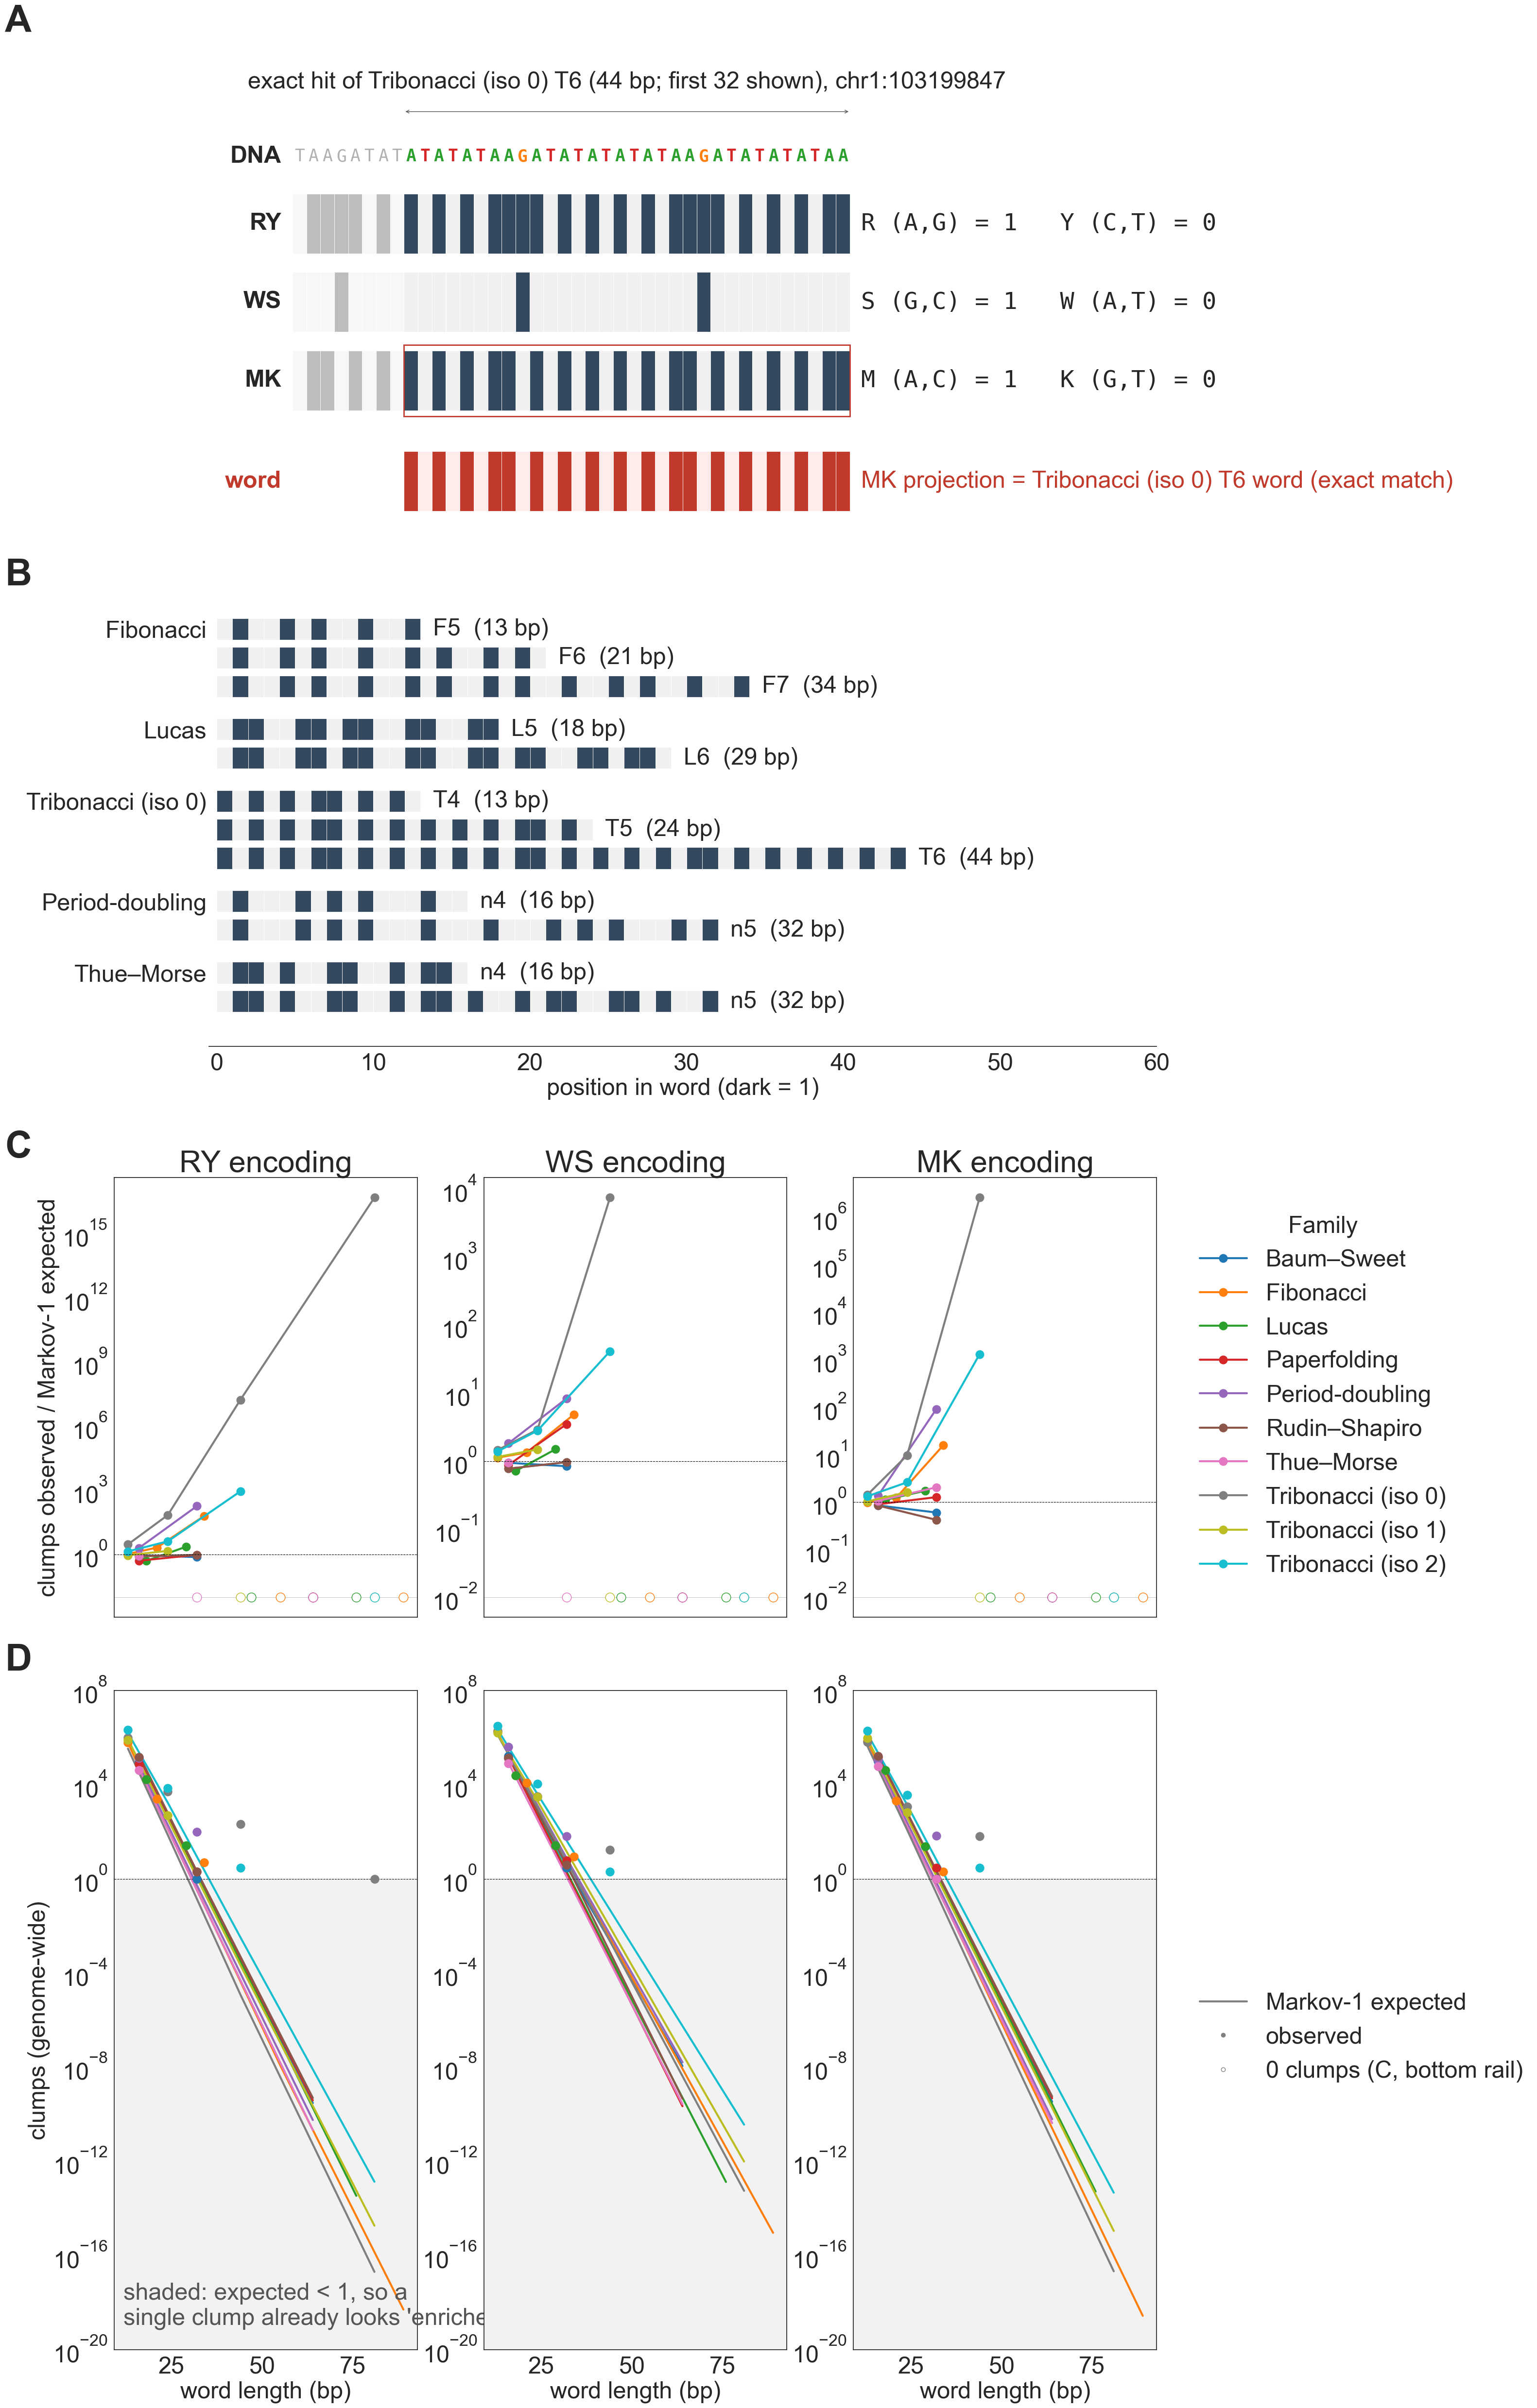

In [5]:
# =====================================================================
#  Figure 1 
#   A  worked example        (old 1A)
#   B  word families         (old 1B)
#   C  observed / expected   (old 2A, one column per encoding)
#   D  absolute clump counts (old 2B)
#
# Assumes the same helpers/globals as your current script:
#   load_loci, load_word_table, project, word_label, make_family_label,
#   save, draw_bits, TAG, BASE_COLORS, PROJECTION_TEXT, MAPPING_ORDER,
#   MAPPING_LABELS, SCAN_FILE, OUTDIR, FIG2_MAX_LENGTH,
#   plt, sns, pd, np, Rectangle, Line2D
# =====================================================================

# ---------------------------------------------------------------------
# Parameters
# ---------------------------------------------------------------------
C_SIZE = (30, 50)               # figure size (inches)
C_MAX_LENGTH = FIG2_MAX_LENGTH  # longest word length plotted in C/D

# vertical blocks (figure coordinates): top = A+B, bottom = C+D
C_TOP_BLOCK = (0.568, 0.9775)     # (bottom, top) of the A/B block
C_BOT_BLOCK = (0.0315, 0.514)     # (bottom, top) of the C/D block
C_TOP_LEFT = 0.15               # left edge of A/B (room for family tick labels in B)
C_BOT_LEFT = 0.085              # left edge of C/D (room for y-axis labels)
C_RIGHT = 0.80                  # right edge of all panels (legends sit to the right)

C_TOP_HEIGHT_RATIOS = [1.05, 1] # A : B
C_TOP_HSPACE = 0.20
C_BOT_HEIGHT_RATIOS = [0.667, 1]  # C : D
C_BOT_HSPACE = 0.134
C_BOT_WSPACE = 0.22

# panel titles (leave "" for none)
C_TITLES = {"A": "", "B": "", "C": "", "D": ""}

# fonts (harmonised across all four panels)
C_PANEL_LABEL_SIZE = 55         # "A" ... "D"
C_TITLE_SIZE = 45               # panel titles and encoding column titles
C_AXIS_LABEL_SIZE = 35          # axis labels
C_TICK_SIZE = 35                # tick labels
C_ROW_LABEL_SIZE = 35           # "DNA", "RY", ... in A
C_DNA_SIZE = 25                 # nucleotide letters in A
C_ANNOT_SIZE = 35               # annotations in A and the shaded-region note in D
C_PROJ_SIZE = 35                # projection text in A
C_WORD_LABEL_SIZE = 35          # "F5 (13 bp)" labels in B
C_LEGEND_SIZE = 35
C_LEGEND_TITLE_SIZE = 35

# panel letter / title placement (figure coordinates)
C_LABEL_X = 0.01                # x of all panel letters (shared -> aligned)
C_TITLE_X = 0.045               # x of all panel titles
C_LABEL_DY = 0.0054              # height of letter above axes top

# panel A
C_N_SHOW = 32
C_FLANK = 8
C_X0 = 6
C_HIT_COLOR = "#c0392b"

# panel B
C_B_XLIM = 60

# panels C / D
C_C_MS, C_C_LW = 12, 3
C_ZERO_S = 180
C_D_LW, C_D_S = 3, 150
C_D_YLIM = (1e-20, 1e8)

# legends (to the right of C/D)
C_LEG_X = 0.815
C_LEG_FAMILY_ANCHOR = (C_LEG_X, 0.424)
C_LEG_KEY_ANCHOR    = (C_LEG_X, 0.16)


# ---------------------------------------------------------------------
# Helpers
# ---------------------------------------------------------------------
def c_panel_header(fig, ax, letter, title=""):
    """Letter (and optional title) at a fixed figure x so all panels align."""
    top = ax.get_position().y1 + C_LABEL_DY
    fig.text(C_LABEL_X, top, letter, ha="left", va="bottom",
             fontsize=C_PANEL_LABEL_SIZE, fontweight="bold")
    if title:
        fig.text(C_TITLE_X, top, title, ha="left", va="bottom",
                 fontsize=C_TITLE_SIZE)


def draw_worked_example(ax):
    """Old Figure 1A."""
    L = load_loci()
    words = load_word_table()
    cand = L[(L.code == "trib0_T6") & (L.mapping == "MK") & (L.form == "word")]
    pref = cand[cand.locus == "chr1:103199847"]
    ex = (pref if not pref.empty
          else cand.sort_values("self_match", ascending=False)).iloc[0]
    n_show, flank, x0 = C_N_SHOW, C_FLANK, C_X0
    seq = ex.left[-flank:] + ex.hit[:n_show]
    word = words["trib0_T6"]

    ax.text(x0 - 0.8, 4.4, "DNA", ha="right", va="center",
            fontsize=C_ROW_LABEL_SIZE, fontweight="bold")
    for i, b in enumerate(seq):
        in_hit = i >= flank
        ax.text(x0 + i + 0.5, 4.4, b.upper(), ha="center", va="center",
                family="monospace", fontsize=C_DNA_SIZE,
                color=BASE_COLORS[b.upper()] if in_hit else "#b0b0b0",
                fontweight="bold" if in_hit else "normal")
    ax.annotate("", xy=(x0 + flank, 5.0), xytext=(x0 + len(seq), 5.0),
                arrowprops=dict(arrowstyle="<->", color="#555", lw=1))
    ax.text(x0 + flank + n_show / 2, 5.25,
            f"exact hit of {word_label(TAG['trib0_T6'])} ({len(word)} bp; "
            f"first {n_show} shown), {ex.locus}",
            ha="center", va="bottom", fontsize=C_ANNOT_SIZE)

    for k, m in enumerate(MAPPING_ORDER):
        y = 3.1 - k * 1.05
        bits = project(seq, m)
        ax.text(x0 - 0.8, y + 0.4, m, ha="right", va="center",
                fontsize=C_ROW_LABEL_SIZE, fontweight="bold")
        draw_bits(ax, x0, y, bits[:flank], colors=("#f7f7f7", "#bdbdbd"))
        draw_bits(ax, x0 + flank, y, bits[flank:],
                  highlight=C_HIT_COLOR if m == "MK" else None)
        ax.text(x0 + len(seq) + 0.8, y + 0.4, PROJECTION_TEXT[m],
                va="center", fontsize=C_PROJ_SIZE, family="monospace")

    y = 3.1 - 3 * 1.05 - 0.3
    ax.text(x0 - 0.8, y + 0.4, "word", ha="right", va="center",
            fontsize=C_ROW_LABEL_SIZE, fontweight="bold", color=C_HIT_COLOR)
    draw_bits(ax, x0 + flank, y, word[:n_show], colors=("#fdecea", C_HIT_COLOR))
    ax.text(x0 + len(seq) + 0.8, y + 0.4,
            f"MK projection = {word_label(TAG['trib0_T6'])} word (exact match)",
            va="center", fontsize=C_ANNOT_SIZE, color=C_HIT_COLOR)

    ax.set_xlim(0, x0 + len(seq) + 22)
    ax.set_ylim(-0.4, 5.8)
    ax.axis("off")


def draw_word_families(ax, scan):
    """Old Figure 1B."""
    scan = scan[scan.mapping == "RY"]
    show = [
        ("fibonacci", "standard", ["F5", "F6", "F7"]),
        ("lucas", "standard", ["L4", "L5", "L6"]),
        ("tribonacci", "isolate_0", ["T4", "T5", "T6"]),
        ("period_doubling", "standard", ["n4", "n5"]),
        ("thue_morse", "standard", ["n4", "n5"]),
    ]
    y = 0
    yt, yl = [], []
    for fam, var, labels in show:
        first = True
        for lab in labels:
            r = scan[(scan.family == fam) & (scan.variant == var) & (scan.label == lab)]
            if r.empty:
                continue
            w = r.word.iloc[0]
            draw_bits(ax, 0, -y, w, cell=1, h=0.75)
            ax.text(len(w) + 0.8, -y + 0.37, f"{lab}  ({len(w)} bp)",
                    va="center", fontsize=C_WORD_LABEL_SIZE)
            yt.append(-y + 0.37)
            yl.append(make_family_label({"family": fam, "variant": var}) if first else "")
            first = False
            y += 1
        y += 0.5
    ax.set_yticks(yt)
    ax.set_yticklabels(yl)
    ax.tick_params(axis="y", length=0, labelsize=C_TICK_SIZE)
    ax.tick_params(axis="x", labelsize=C_TICK_SIZE)
    ax.set_xlim(-0.5, C_B_XLIM)
    ax.set_ylim(-y + 0.3, 1.2)
    ax.set_xlabel("position in word (dark = 1)", fontsize=C_AXIS_LABEL_SIZE)
    sns.despine(ax=ax, left=True)


def draw_enrichment(axes_c, axes_d, df, palette):
    """Old Figure 2A (axes_c) and 2B (axes_d), one column per encoding."""
    pos = df.loc[df.clumps_obs_over_markov1 > 0, "clumps_obs_over_markov1"]
    rail = 10 ** (np.floor(np.log10(pos.min())) - 1)

    for j, m in enumerate(MAPPING_ORDER):
        sub = df[df.mapping == m]

        # ---- C: observed / expected ----
        ax = axes_c[j]
        for fam, x in sub.groupby("family_label"):
            x = x.sort_values("length")
            seen = x[x.observed_clumps > 0]
            zero = x[(x.observed_clumps == 0) & (x.expected_clumps_markov1 > 0)]
            ax.plot(seen.length, seen.clumps_obs_over_markov1, "-o",
                    color=palette[fam], ms=C_C_MS, lw=C_C_LW, label=fam)
            ax.scatter(zero.length, np.full(len(zero), rail),
                       facecolor="white", edgecolor=palette[fam],
                       s=C_ZERO_S, zorder=3)
        ax.axhline(1, color="black", lw=0.8, ls="--")
        ax.axhline(rail, color="#bbb", lw=0.6)
        ax.set_yscale("log")
        ax.set_title(f"{MAPPING_LABELS[m]} encoding", fontsize=C_TITLE_SIZE)
        ax.tick_params(labelsize=C_TICK_SIZE)
        ax.tick_params(axis="x", labelbottom=False)
        if j == 0:
            ax.set_ylabel("clumps observed / Markov-1 expected",
                          fontsize=C_AXIS_LABEL_SIZE)

        # ---- D: absolute clump counts ----
        ax = axes_d[j]
        for fam, x in sub.groupby("family_label"):
            x = x.sort_values("length")
            x = x[x.expected_clumps_markov1 > 0]
            ax.plot(x.length, x.expected_clumps_markov1, "-",
                    color=palette[fam], lw=C_D_LW)
            s = x[x.observed_clumps > 0]
            ax.scatter(s.length, s.observed_clumps, color=palette[fam],
                       s=C_D_S, zorder=3)
        ax.axhline(1, color="black", lw=0.8, ls="--")
        ax.axhspan(1e-300, 1, color="#f2f2f2", zorder=0)
        ax.set_yscale("log")
        ax.set_ylim(*C_D_YLIM)
        ax.set_xlabel("word length (bp)", fontsize=C_AXIS_LABEL_SIZE)
        ax.tick_params(labelsize=C_TICK_SIZE)
        if j == 0:
            ax.set_ylabel("clumps (genome-wide)", fontsize=C_AXIS_LABEL_SIZE)
            ax.text(0.03, 0.03, "shaded: expected < 1, so a\n"
                    "single clump already looks 'enriched'",
                    transform=ax.transAxes,
                    fontsize=C_ANNOT_SIZE, color="#555", va="bottom", ha="left")


# ---------------------------------------------------------------------
# Figure
# ---------------------------------------------------------------------
def plot_combined():
    scan = pd.read_csv(SCAN_FILE, dtype={"word": str})
    for c in ["length", "observed_clumps", "expected_clumps_markov1",
              "clumps_obs_over_markov1"]:
        scan[c] = pd.to_numeric(scan[c], errors="coerce")

    df = scan[scan.length <= C_MAX_LENGTH].copy()
    df["family_label"] = df.apply(make_family_label, axis=1)
    fams = sorted(df.family_label.unique())
    palette = dict(zip(fams, sns.color_palette("tab10", len(fams))))

    fig = plt.figure(figsize=C_SIZE)

    # top block: A, B
    gs_top = fig.add_gridspec(2, 1, height_ratios=C_TOP_HEIGHT_RATIOS,
                              hspace=C_TOP_HSPACE,
                              left=C_TOP_LEFT, right=C_RIGHT,
                              bottom=C_TOP_BLOCK[0], top=C_TOP_BLOCK[1])
    ax_a = fig.add_subplot(gs_top[0])
    ax_b = fig.add_subplot(gs_top[1])

    # bottom block: C, D (3 encodings each)
    gs_bot = fig.add_gridspec(2, 3, height_ratios=C_BOT_HEIGHT_RATIOS,
                              hspace=C_BOT_HSPACE, wspace=C_BOT_WSPACE,
                              left=C_BOT_LEFT, right=C_RIGHT,
                              bottom=C_BOT_BLOCK[0], top=C_BOT_BLOCK[1])
    axes_c, axes_d = [], []
    for j in range(3):
        ac = fig.add_subplot(gs_bot[0, j], sharex=axes_c[0] if axes_c else None)
        ad = fig.add_subplot(gs_bot[1, j], sharex=ac)
        axes_c.append(ac)
        axes_d.append(ad)

    draw_worked_example(ax_a)
    draw_word_families(ax_b, scan)
    draw_enrichment(axes_c, axes_d, df, palette)

    # legends for C/D, in the right margin
    handles = [Line2D([0], [0], color=palette[f], marker="o", lw=C_C_LW, markersize=C_C_MS) for f in fams]
    fig.legend(handles, fams, loc="center left", frameon=False,
               bbox_to_anchor=C_LEG_FAMILY_ANCHOR, title="Family",
               fontsize=C_LEGEND_SIZE, title_fontsize=C_LEGEND_TITLE_SIZE)
    extra = [Line2D([0], [0], color="grey", lw=C_D_LW),
             Line2D([0], [0], color="grey", marker="o", lw=0),
             Line2D([0], [0], marker="o", lw=0, markerfacecolor="white",
                    markeredgecolor="grey")]
    fig.legend(extra, ["Markov-1 expected", "observed", "0 clumps (C, bottom rail)"],
               loc="center left", frameon=False, bbox_to_anchor=C_LEG_KEY_ANCHOR,
               fontsize=C_LEGEND_SIZE)

    # panel letters (C sits above the encoding column titles)
    c_panel_header(fig, ax_a, "A", C_TITLES["A"])
    c_panel_header(fig, ax_b, "B", C_TITLES["B"])
    c_panel_header(fig, axes_c[0], "C", C_TITLES["C"])
    c_panel_header(fig, axes_d[0], "D", C_TITLES["D"])

    save(fig, "fig1_combined_method_enrichment")


print("Combined figure: method + enrichment ...")
plot_combined()

## Figure 2. Decoy test, all words

Every word × encoding with at least one locus (real word or decoy): genome-wide loci of the real
word (star; open = fewer than 19 decoys, not testable) against its run-permutation decoys (same
length, composition and run lengths, distinct, not the word in any form). The words with no locus
at all are listed in the footnote.

36 words in the decoy test; nearly periodic: Period-doubling n4, Paperfolding n5, Period-doubling n5, Tribonacci (iso 0) T6, Lucas L7, Fibonacci F8, Paperfolding n6, Period-doubling n6, Tribonacci (iso 0) T7
Figure 2: decoy test, all words ...


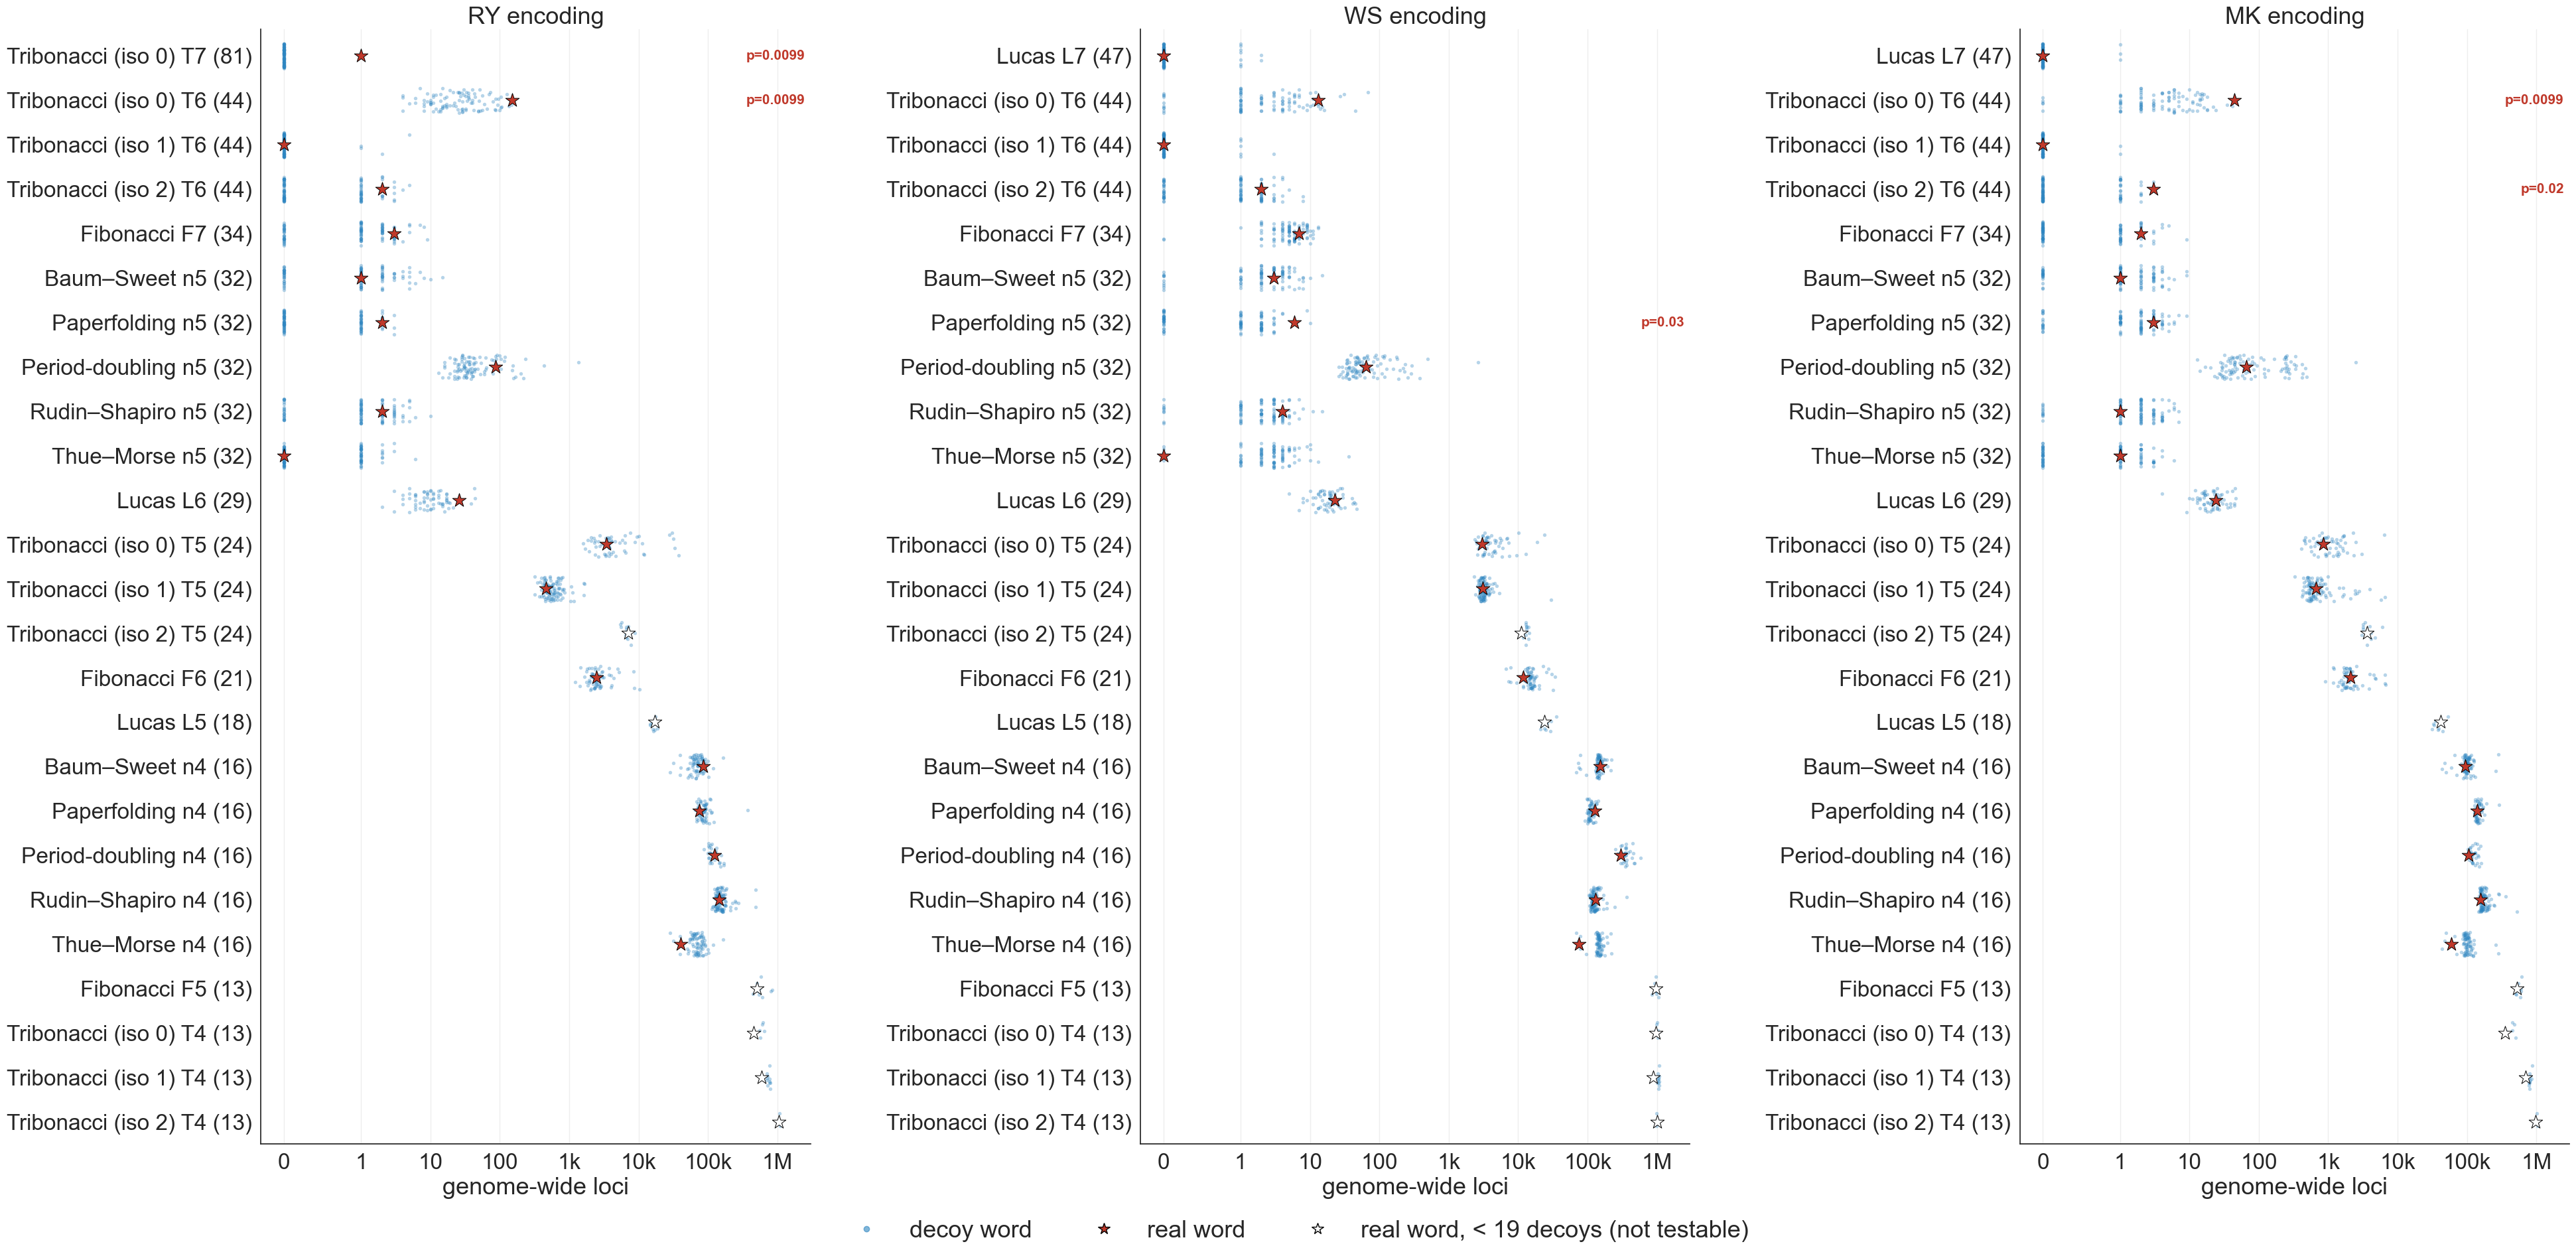

In [6]:
# =====================================================================
# Figure 2 parameters
# =====================================================================
F2_SIZE = FIG2_SIZE             # figure size (inches)
F2_WSPACE = 0.6                 # horizontal gap between encodings
F2_MARGINS = dict(left=0.11, right=0.98, top=0.92, bottom=0.08)

# fonts
F2_SUPTITLE_SIZE = 14           # figure title
F2_TITLE_SIZE = 26              # column titles ("RY encoding" ...)
F2_YTICK_SIZE = 24               # word labels on the y axis
F2_XTICK_SIZE = 24              # loci tick labels
F2_AXIS_LABEL_SIZE = 26         # x-axis label
F2_PVAL_SIZE = 15               # "p=..." annotations
F2_LEGEND_SIZE = 26             # legend entries
F2_NOTE_SIZE = 10               # footnote text

# markers
F2_DECOY_S = 15                # decoy dot size
F2_DECOY_ALPHA = 0.35
F2_DECOY_JITTER = 0.28          # vertical jitter of decoys
F2_REAL_S = 240                 # real-word star size
F2_LEGEND_MS = 13               # star size in legend

# axes / annotation
F2_P_THRESHOLD = 0.05           # p-values at or below this are printed
F2_XTICKS = [0, 1, 10, 100, 1e3, 1e4, 1e5, 1e6]
F2_XTICKLABELS = ["0", "1", "10", "100", "1k", "10k", "100k", "1M"]
F2_XLIM = (-0.3, 3e6)

# placement (figure coordinates)
F2_SUPTITLE_Y = 0.995
F2_LEGEND_ANCHOR = (0.5, 0.020)   # (x, y) of the legend's bottom-centre point
F2_MARGINS = dict(left=0.11, right=0.98, top=0.95, bottom=0.11)
F2_NOTE_XY = (0.01, 0.005)

F2_COLOR_DECOY = "#2e86c1"
F2_COLOR_REAL = "#c0392b"


def decoy_strip(ax, decoys, real, value, order, extra=None, p_table=None, ylabel="",
                decoy_label="decoy word", extra_label="random word", status=None):
    """Strip plot of decoys per category; `status` maps a category to a text shown (in grey)
    instead of its p-value, e.g. 'no loci' or 'no decoys'."""
    status = status or {}
    r = rng()
    pos = {c: i for i, c in enumerate(order)}
    decoys = decoys[decoys.cat.isin(order)]
    sns.boxplot(data=decoys, x="cat", y=value, order=order, showfliers=False, width=0.55,
                color="#d6eaf8", linewidth=0.8, ax=ax)
    xj = decoys.cat.map(pos) + r.uniform(-0.2, 0.2, len(decoys))
    ax.scatter(xj, decoys[value], s=9, alpha=0.4, color="#2e86c1", lw=0, zorder=3,
               label=decoy_label)
    if extra is not None:
        extra = extra[extra.cat.isin(order)]
        xe = extra.cat.map(pos) + r.uniform(-0.12, 0.12, len(extra)) + 0.3
        ax.scatter(xe, extra[value], s=22, marker="x", color="#7d3c98", zorder=4,
                   label=extra_label)
    real = real[real.cat.isin(order)]
    ax.scatter(real.cat.map(pos), real[value], marker="*", s=230, color="#c0392b",
               edgecolor="black", lw=0.7, zorder=10, label="real word")
    symlog_axis(ax)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels([c.split("|")[1] for c in order], fontsize=9)
    for lab, c in zip(ax.get_xticklabels(), order):
        if status.get(c) == "no loci":
            lab.set_color("#aaa")
    groups = {}
    for i, c in enumerate(order):
        groups.setdefault(c.split("|")[0], []).append(i)
    trans = matplotlib.transforms.blended_transform_factory(ax.transData, ax.transAxes)
    for name, idx in groups.items():
        ax.text(np.mean(idx), -0.07, textwrap.fill(name, 14), transform=trans, ha="center",
                va="top", fontsize=FONT_SIZE - 2, fontweight="bold")
    ymax = ax.get_ylim()[1]
    if p_table is not None:
        for c in order:
            p = p_table.get(c)
            if c in status:
                ax.text(pos[c], ymax * 1.4, status[c], ha="center", fontsize=ANNOT_SIZE,
                        color="#aaa", style="italic", va="bottom", rotation=90)
            elif p is not None and pd.notna(p):
                ax.text(pos[c], ymax * 1.4, f"{p:.2g}", ha="center", fontsize=ANNOT_SIZE,
                        color="#c0392b" if p < 0.05 else "#555", rotation=90,
                        fontweight="bold" if p < 0.05 else "normal", va="bottom")
        ax.set_ylim(top=ymax * 60)
    prev = None
    for i, c in enumerate(order):
        p = c.split("|")[0]
        if prev is not None and p != prev:
            ax.axvline(i - 0.5, color="#ddd", lw=0.8)
        prev = p


def periodic_decoys(pattern_tag, mapping, mode):
    """Periodic decoys for one pattern, mapping and mode: strict, or relaxed if the strict
    rules give fewer than 19 and the relaxed run has more."""
    st = PER[(PER.pattern == pattern_tag) & (PER.mapping == mapping)
             & (PER.kind == "DECOY") & (PER["mode"] == mode)]
    if len(st) >= 19 or PER_NR is None:
        return st, "strict"
    nr = PER_NR[(PER_NR.pattern == pattern_tag) & (PER_NR.mapping == mapping)
                & (PER_NR.kind == "DECOY") & (PER_NR["mode"] == mode)]
    return (nr, "relaxed") if len(nr) > len(st) else (st, "strict")


def run_decoy_table():
    """Empirical p of every word × encoding against its run-permutation decoys."""
    rows = []
    for (tag, m), x in DEC.groupby(["pattern", "mapping"]):
        real = x[x.kind == "REAL"].loci.iloc[0]
        d = x[x.kind == "DECOY"].loci
        k, n, pe = empirical_p(real, d)
        rows.append(dict(panel="3A", pattern=tag, word=word_label(tag), mapping=m,
                         length=int(x.length.iloc[0]), control="run permutation", metric="loci",
                         real=real, n_decoys=n, decoy_median=d.median(), decoy_max=d.max(),
                         k_decoys_ge_real=k, p_emp=pe, testable=n >= 19))
    t = pd.DataFrame(rows)
    q = DSUM.set_index(["pattern", "mapping"]).q_emp_loci
    t["q_emp_loci"] = [q.get((a, b), np.nan) for a, b in zip(t.pattern, t.mapping)]
    return t


def periodic_table(tags):
    rows, dec = [], []
    for tag in tags:
        for m in MAPPING_ORDER:
            x = PER[(PER.pattern == tag) & (PER.mapping == m)]
            if x.empty:
                continue
            real = int(x[x.kind == "REAL"].loci.iloc[0])
            til = int(x[x.kind == "TILING"].loci.iloc[0])
            for mode in ["random_unit", "same_unit"]:
                d, rule = periodic_decoys(tag, m, mode)
                k, n, pe = empirical_p(real, d.loci) if len(d) else (0, 0, np.nan)
                rows.append(dict(panel="3B", pattern=tag, word=word_label(tag), mapping=m,
                                 control=mode, rule=rule, metric="loci", real=real, tiling=til,
                                 n_decoys=n, decoy_median=d.loci.median() if n else np.nan,
                                 decoy_max=d.loci.max() if n else np.nan,
                                 k_decoys_ge_real=k, p_emp=pe))
                dec.append(d.assign(mode=mode))
    dec = pd.concat(dec) if dec else pd.DataFrame(columns=["pattern", "mapping", "loci", "mode"])
    return pd.DataFrame(rows), dec


def plot_fig2():
    tab_a = run_decoy_table()
    shown = tab_a[(tab_a.real > 0) | (tab_a.decoy_max > 0)]
    absent = sorted(set(tab_a.pattern) - set(shown.pattern), key=lambda t: (len(WORDS[t]), t))

    fig, axes = plt.subplots(1, 3, figsize=F2_SIZE, gridspec_kw={"wspace": F2_WSPACE})
    for j, (ax, m) in enumerate(zip(axes, MAPPING_ORDER)):
        sub = shown[shown.mapping == m].sort_values(["length", "word"], ascending=[False, True])
        sub = sub.reset_index(drop=True)
        r = rng()
        for i, row in sub.iterrows():
            d = DEC[(DEC.pattern == row.pattern) & (DEC.mapping == m) & (DEC.kind == "DECOY")].loci
            ax.scatter(d, i + r.uniform(-F2_DECOY_JITTER, F2_DECOY_JITTER, len(d)),
                       s=F2_DECOY_S, color=F2_COLOR_DECOY, alpha=F2_DECOY_ALPHA,
                       lw=0, zorder=2)
            ax.scatter(row.real, i, marker="*", s=F2_REAL_S, zorder=4,
                       color=F2_COLOR_REAL if row.testable else "white",
                       edgecolor="black", lw=0.7)
            if row.p_emp <= F2_P_THRESHOLD:
                ax.text(0.99, i, f"p={row.p_emp:.2g}", transform=ax.get_yaxis_transform(),
                        va="center", ha="right", fontsize=F2_PVAL_SIZE, color=F2_COLOR_REAL,
                        fontweight="bold")
        ax.set_xscale("symlog", linthresh=1)
        ax.set_xticks(F2_XTICKS)
        ax.set_xticklabels(F2_XTICKLABELS, fontsize=F2_XTICK_SIZE)
        ax.set_xlim(*F2_XLIM)
        ax.set_yticks(range(len(sub)))
        ax.set_yticklabels([f"{w} ({l})" for w, l in zip(sub.word, sub.length)],
                           fontsize=F2_YTICK_SIZE)
        ax.set_ylim(len(sub) - 0.5, -0.6)
        ax.set_xlabel("genome-wide loci", fontsize=F2_AXIS_LABEL_SIZE)
        ax.set_title(f"{m} encoding", fontsize=F2_TITLE_SIZE)
        ax.grid(axis="x", color="#eee")
        sns.despine(ax=ax)

    handles = [Line2D([0], [0], marker="o", lw=0, color=F2_COLOR_DECOY, alpha=0.6,
                      label="decoy word"),
               Line2D([0], [0], marker="*", lw=0, color=F2_COLOR_REAL, markeredgecolor="black",
                      markersize=F2_LEGEND_MS, label="real word"),
               Line2D([0], [0], marker="*", lw=0, color="white", markeredgecolor="black",
                      markersize=F2_LEGEND_MS, label="real word, < 19 decoys (not testable)")]
    fig.legend(handles=handles, frameon=False, ncol=3, fontsize=F2_LEGEND_SIZE,
               loc="lower center", bbox_to_anchor=F2_LEGEND_ANCHOR)

    fig.subplots_adjust(**F2_MARGINS)
    save(fig, "fig2_decoy_test_all_words")

    tab_a.to_csv(OUTDIR / "fig2_decoy_empirical_p.csv", index=False)
    return tab_a


DEC = pd.read_csv(DECOY_FILE, dtype={"word": str})
DSUM = pd.read_csv(DECOY_SUMMARY_FILE)
PROFILE = pd.read_csv(PERIODIC_PROFILE_FILE, dtype={"unit": str})
PER = pd.read_csv(PERIODIC_FILE, dtype={"word": str, "unit": str})
PER_NR = (pd.read_csv(PERIODIC_NR_FILE, dtype={"word": str, "unit": str})
          if PERIODIC_NR_FILE.exists() else None)
WORDS = load_words_by_tag()
NEAR_TAGS = sorted(PROFILE[PROFILE.near_periodic.astype(bool)].pattern,
                   key=lambda t: (len(WORDS[t]), t))
print(f"{DEC.pattern.nunique()} words in the decoy test; nearly periodic: "
      + ", ".join(word_label(t) for t in NEAR_TAGS))

print("Figure 2: decoy test, all words ...")
TAB3A = plot_fig2()

## Figure 3. What the hits are

Figure 3: hit context ...


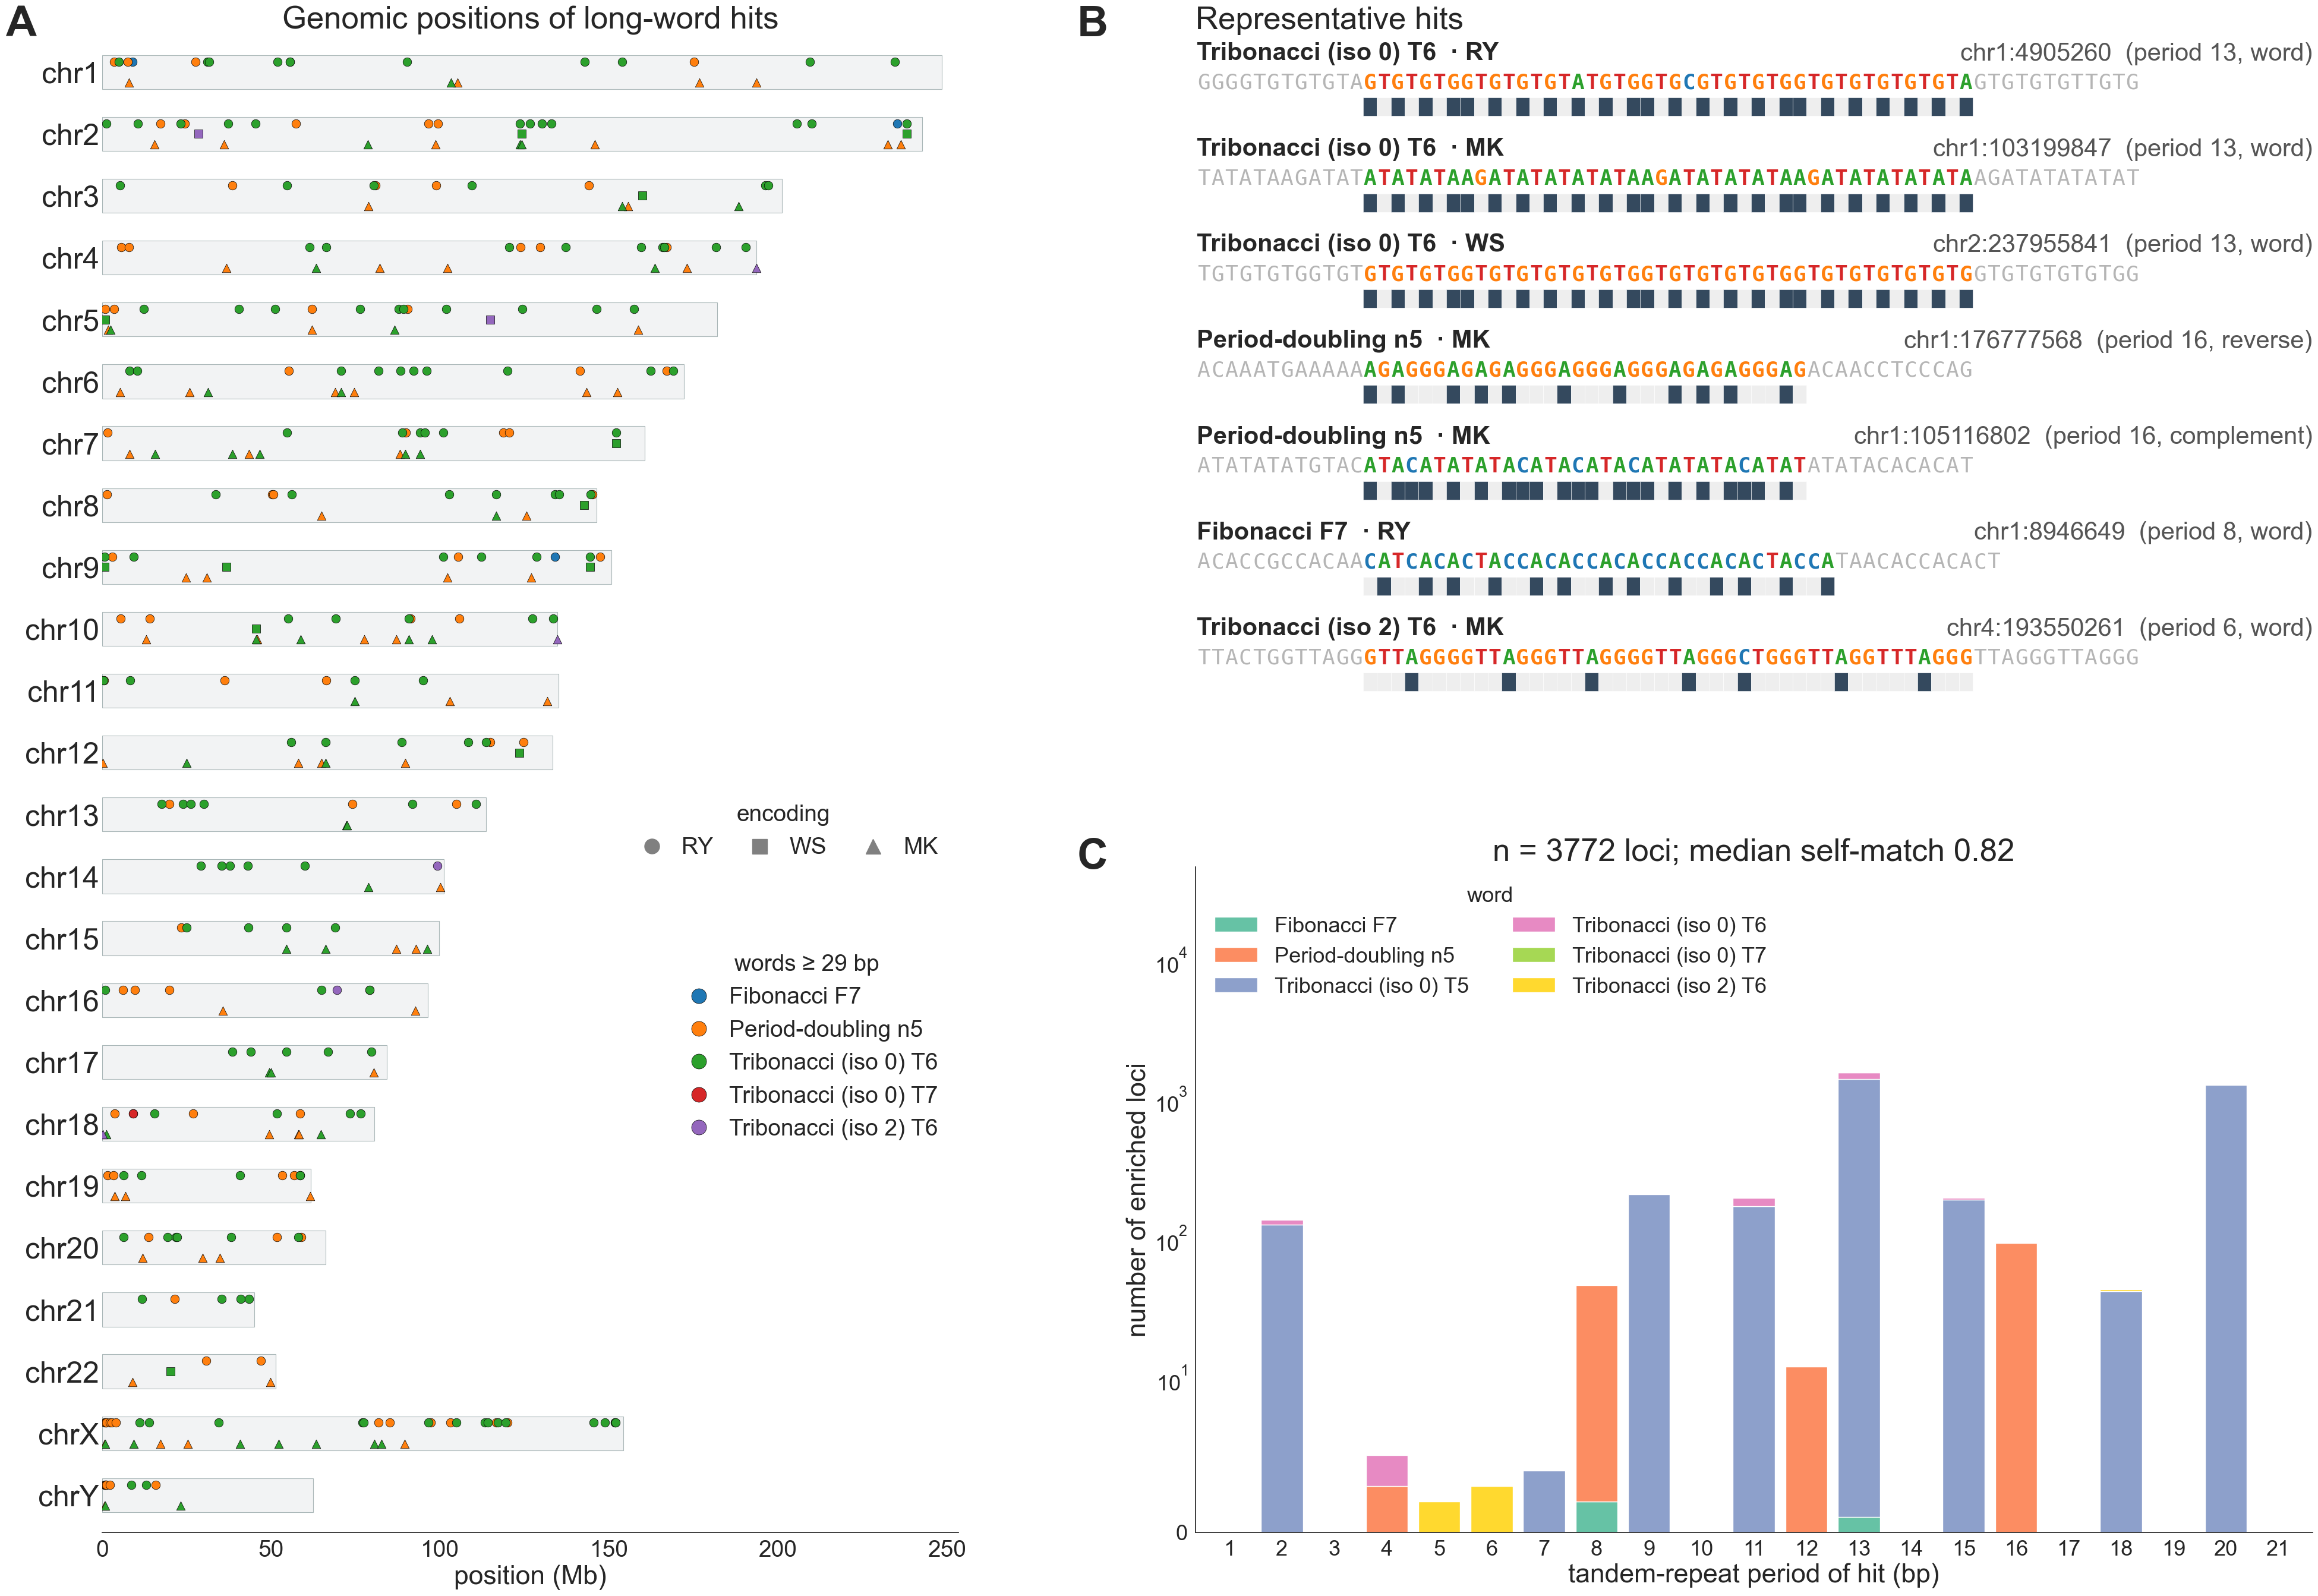

Projection check: {'complement': 1494, 'word': 1227, 'reverse': 628, 'reverse_complement': 423}


In [11]:
# =====================================================================
# Figure 3 parameters
#   A = ideogram (left, full height)
#   B = representative sequences (top right)
#   C = tandem-period bar chart (bottom right)
# =====================================================================
F3_SIZE = FIG3_SIZE                 # figure size (inches)
F3_WIDTH_RATIOS = [1.15, 1.5]       # A : B/C column
F3_HEIGHT_RATIOS = [1, 1]           # B : C (right column)
F3_HSPACE = 0.25                    # gap between B and C
F3_WSPACE = 0.24                    # gap between A and B/C
F3_MARGINS = dict(left=0.06, right=0.99, top=0.90, bottom=0.06)

# panel letters
F3_PANEL_LABEL_SIZE = 52           # "A", "B", "C"
F3_LABEL_PAD = 0.008                # gap (fig. fraction) between letter and panel's leftmost element

# ---------------- A: ideogram ----------------------------------------
F3_A_TITLE = ("Genomic positions of long-word hits")
              
F3_A_TITLE_SIZE = 38
F3_A_AXIS_LABEL_SIZE = 32
F3_A_XTICK_SIZE = 28
F3_A_YTICK_SIZE = 36                # chromosome names
F3_A_LEGEND_SIZE = 28
F3_A_LEGEND_TITLE_SIZE = 28
F3_A_MARKER_S = 110                 # scatter marker area (points^2)
F3_A_MARKER_LW = 0.5
F3_A_LEGEND_MARKER_SIZE = 18        # legend symbol size (points)
F3_A_ENC_OFFSETS = {"RY": -0.17, "WS": 0.0, "MK": 0.17}  # vertical offset per encoding
F3_A_CHROM_HEIGHT = 0.55            # height of chromosome bars
# legends sit in the empty area right of the short chromosomes (axes coords)
F3_A_ENC_LEGEND_ANCHOR = (1.0, 0.50)
F3_A_WORD_LEGEND_ANCHOR = (1.0, 0.40)

# ---------------- B: sequences ---------------------------------------
F3_B_TITLE = ("Representative hits")

F3_B_TITLE_SIZE = 38
F3_B_ROW_LABEL_SIZE = 30            # word · encoding · locus label above each sequence
F3_B_DNA_SIZE = 26                  # nucleotide letters
F3_B_EXTRA_SIZE = 22                # "(+N bp)"
F3_B_LEGEND_SIZE = 22               # base-colour legend
F3_FLANK = 12                       # flanking bases shown on each side
F3_MAXHIT = 50                      # longest part of a hit shown
F3_X_SEQ = 0                        # x where sequences start (labels are now above, not left)
F3_ROW_STEP = 2.6                   # vertical distance between examples (label + bases + strip)
F3_B_LABEL_DY = 1.15                # height of the label above the strip's row centre
F3_B_LEGEND_ANCHOR = (1.0, 1.06)
F3_B_LEGEND_NCOL = 4

# ---------------- C: tandem period -----------------------------------
F3_C_TITLE_SIZE = 38
F3_C_AXIS_LABEL_SIZE = 32
F3_C_XTICK_SIZE = 26
F3_C_YTICK_SIZE = 26
F3_C_LEGEND_SIZE = 26
F3_C_LEGEND_TITLE_SIZE = 26
F3_C_BAR_WIDTH = 0.8
F3_C_LINTHRESH = 10                 # symlog linear threshold
F3_C_YTOP_FACTOR = 30               # y headroom for the legend
F3_C_LEGEND_NCOL = 2


def plot_fig3():
    L = load_loci()
    scan = pd.read_csv(SCAN_FILE, dtype={"word": str}).drop_duplicates(["family", "variant", "label"])
    words_by_tag = dict(zip(scan.family + "/" + scan.variant + "/" + scan.label, scan.word))
    L = check_projection_convention(L, words_by_tag)
    L.drop(columns=["dna"]).to_csv(OUTDIR / "fig3_context_hits_checked.csv", index=False)

    fig = plt.figure(figsize=F3_SIZE)
    gs = gridspec.GridSpec(2, 2, height_ratios=F3_HEIGHT_RATIOS,
                           width_ratios=F3_WIDTH_RATIOS, hspace=F3_HSPACE, wspace=F3_WSPACE)

    # ---------------- A: ideogram (left, full height) ----------
    # drawn first so it never covers B's row labels
    axA = fig.add_subplot(gs[:, 0])
    sizes = load_chrom_sizes()
    chroms = [c for c in CHM13_SIZES if c in sizes]
    ypos = {c: i for i, c in enumerate(chroms)}
    h = F3_A_CHROM_HEIGHT
    for c in chroms:
        axA.add_patch(Rectangle((0, ypos[c] - h / 2), sizes[c] / 1e6, h,
                                facecolor="#f2f3f4", edgecolor="#aab7b8", lw=0.8))
    longw = L[L.length >= FIG5_MIN_WORD_LENGTH].copy()
    longw["word_label"] = [word_label(t) for t in longw.tag]
    wl = sorted(longw.word_label.unique())
    pal = dict(zip(wl, sns.color_palette("tab10", len(wl))))
    for (wlab, m), x in longw.groupby(["word_label", "mapping"]):
        x = x[x.chrom.isin(ypos)]
        axA.scatter(x.start / 1e6, x.chrom.map(ypos) + F3_A_ENC_OFFSETS[m],
                    marker=MAPPING_MARKERS[m], s=F3_A_MARKER_S, color=pal[wlab],
                    edgecolor="black", lw=F3_A_MARKER_LW, zorder=3)
    axA.set_yticks(range(len(chroms)))
    axA.set_yticklabels(chroms, fontsize=F3_A_YTICK_SIZE)
    axA.tick_params(axis="x", labelsize=F3_A_XTICK_SIZE)
    axA.set_ylim(len(chroms) - 0.4, -0.6)                 # inverted: chr1 on top
    axA.set_xlabel("position (Mb)", fontsize=F3_A_AXIS_LABEL_SIZE)
    axA.set_xlim(0, max(sizes[c] for c in chroms) / 1e6 * 1.02)
    sns.despine(ax=axA, left=True)
    axA.tick_params(axis="y", length=0)
    h1 = [Line2D([0], [0], marker="o", lw=0, color=pal[w], label=w,
                 markersize=F3_A_LEGEND_MARKER_SIZE, markeredgecolor="black",
                 markeredgewidth=F3_A_MARKER_LW)
          for w in wl]
    h2 = [Line2D([0], [0], marker=MAPPING_MARKERS[m], lw=0, color="grey", label=m,
                 markersize=F3_A_LEGEND_MARKER_SIZE)
          for m in MAPPING_ORDER]
    leg = axA.legend(handles=h2, frameon=False, fontsize=F3_A_LEGEND_SIZE,
                     loc="upper right", bbox_to_anchor=F3_A_ENC_LEGEND_ANCHOR,
                     ncol=len(h2), title="encoding", title_fontsize=F3_A_LEGEND_TITLE_SIZE,
                     columnspacing=1.0, handletextpad=0.3)
    axA.add_artist(leg)
    axA.legend(handles=h1, frameon=False, fontsize=F3_A_LEGEND_SIZE,
               loc="upper right", bbox_to_anchor=F3_A_WORD_LEGEND_ANCHOR,
               title=f"words ≥ {FIG5_MIN_WORD_LENGTH} bp",
               title_fontsize=F3_A_LEGEND_TITLE_SIZE, handletextpad=0.3)
    axA.set_title(F3_A_TITLE, fontsize=F3_A_TITLE_SIZE)

    # ---------------- B: sequences (top right) -----------------
    axB = fig.add_subplot(gs[0, 1])
    flank, maxhit, x_seq, step = F3_FLANK, F3_MAXHIT, F3_X_SEQ, F3_ROW_STEP
    rows, used = [], set()
    for code, m, locus in FIG5_EXAMPLES:
        cand = L[(L.code == code) & (L.mapping == m) & ~L.locus.isin(used)]
        pick = cand[cand.locus == locus] if locus else cand.iloc[0:0]
        if pick.empty:
            pick = cand.sort_values(["self_match", "n_hits"], ascending=False)
        if not pick.empty:
            rows.append(pick.iloc[0])
            used.add(pick.iloc[0].locus)
    for i, r in enumerate(rows):
        y = -i * step
        hit = r.hit[:maxhit]
        seq = r.left[-flank:] + hit + r.right[:flank]
        axB.text(x_seq - 0.5, y + F3_B_LABEL_DY,
                 f"{word_label(r.tag)}  · {r.mapping}", ha="left", va="center",
                 fontsize=F3_B_ROW_LABEL_SIZE, fontweight="bold")
        axB.text(x_seq + flank * 2 + maxhit + 6, y + F3_B_LABEL_DY,
                 f"{r.locus}  (period {r.tandem_period}, {r.form.replace('_', ' ')})",
                 ha="right", va="center", fontsize=F3_B_ROW_LABEL_SIZE, color="#555")
        for k, b in enumerate(seq):
            in_hit = flank <= k < flank + len(hit)
            axB.text(x_seq + k, y + 0.35, b.upper(), ha="center", va="center",
                     family="monospace", fontsize=F3_B_DNA_SIZE,
                     color=BASE_COLORS.get(b.upper(), "k") if in_hit else "#b5b5b5",
                     fontweight="bold" if in_hit else "normal")
        bits = project(hit, r.mapping)
        for k, b in enumerate(bits):
            axB.add_patch(Rectangle((x_seq + flank + k - 0.5, y - 0.55), 1, 0.5,
                                    facecolor="#34495e" if b == "1" else "#eeeeee",
                                    edgecolor="white", lw=0.4))
        if len(r.hit) > maxhit:
            axB.text(x_seq + flank + maxhit + flank + 0.8, y + 0.35,
                     f"(+{len(r.hit) - maxhit} bp)", fontsize=F3_B_EXTRA_SIZE,
                     color="#777", va="center")
    axB.set_xlim(x_seq - 0.6, x_seq + flank * 2 + maxhit + 6)
    axB.set_ylim(-(len(rows) - 1) * step - 0.8, F3_B_LABEL_DY + 0.5)
    axB.axis("off")
    axB.set_title(F3_B_TITLE, fontsize=F3_B_TITLE_SIZE, loc="left")
    handles = [Line2D([0], [0], marker="s", lw=0, color=c, label=b) for b, c in BASE_COLORS.items()]


    # ---------------- C: tandem period (bottom right) ----------
    axC = fig.add_subplot(gs[1, 1])
    L["pattern_label"] = [word_label(t) for t in L.tag]
    tab = L.groupby(["tandem_period", "pattern_label"]).size().unstack(fill_value=0)
    tab = tab.reindex(range(1, max(tab.index) + 2), fill_value=0)
    tab.plot(kind="bar", stacked=True, ax=axC, width=F3_C_BAR_WIDTH,
             color=sns.color_palette("Set2", tab.shape[1]))
    axC.set_yscale("symlog", linthresh=F3_C_LINTHRESH)
    axC.set_ylim(0, tab.sum(axis=1).max() * F3_C_YTOP_FACTOR)      # room for the legend
    axC.set_xlabel("tandem-repeat period of hit (bp)", fontsize=F3_C_AXIS_LABEL_SIZE)
    axC.set_ylabel("number of enriched loci", fontsize=F3_C_AXIS_LABEL_SIZE)
    axC.tick_params(axis="x", rotation=0, labelsize=F3_C_XTICK_SIZE)
    axC.tick_params(axis="y", labelsize=F3_C_YTICK_SIZE)
    axC.legend(frameon=False, fontsize=F3_C_LEGEND_SIZE, title="word",
               title_fontsize=F3_C_LEGEND_TITLE_SIZE, ncol=F3_C_LEGEND_NCOL, loc="upper left")
    axC.set_title(f"n = {len(L)} loci; median self-match {L.self_match.median():.2f}",
                  fontsize=F3_C_TITLE_SIZE)
    sns.despine(ax=axC)

    fig.subplots_adjust(**F3_MARGINS)

    # ---------------- panel letters ----------------------------
    # measured after drawing: each letter sits just left of its panel's
    # leftmost element, level with the top of its title.
    fig.canvas.draw()
    rend = fig.canvas.get_renderer()
    to_fig = fig.transFigure.inverted()

    def left_edge(ax):
        return ax.get_tightbbox(rend).transformed(to_fig).x0

    def title_top(ax):
        return ax.title.get_window_extent(rend).transformed(to_fig).y1

    x_a = left_edge(axA) - F3_LABEL_PAD
    x_bc = min(left_edge(axB), left_edge(axC)) - F3_LABEL_PAD   # B and C aligned
    y_top = max(title_top(axA), title_top(axB))                 # A and B aligned
    for x, yy, letter in [(x_a, y_top, "A"), (x_bc, y_top, "B"),
                          (x_bc, title_top(axC), "C")]:
        fig.text(max(x, 0.002), yy, letter, ha="right" if x > 0.03 else "left",
                 va="top", fontsize=F3_PANEL_LABEL_SIZE, fontweight="bold")

    save(fig, "fig3_hit_context")
    longw.drop(columns=["dna"]).to_csv(OUTDIR / "fig3_long_word_loci.csv", index=False)
    return L


print("Figure 3: hit context ...")
ctx = plot_fig3()

print("Projection check:", ctx.matches.value_counts().to_dict())

## Figure 4. Mathematical words occur no more often than words of the same shape in seven complete primate genomes.

wrote /Users/kleiopapatheodorou/Documents/lab/fibonacci/patterns/results_new/all_genomes/fig_primates.pdf /Users/kleiopapatheodorou/Documents/lab/fibonacci/patterns/results_new/all_genomes/fig_primates.png | with results: chm13, chimpanzee, bonobo, gorilla, sumatran_orangutan, bornean_orangutan, siamang


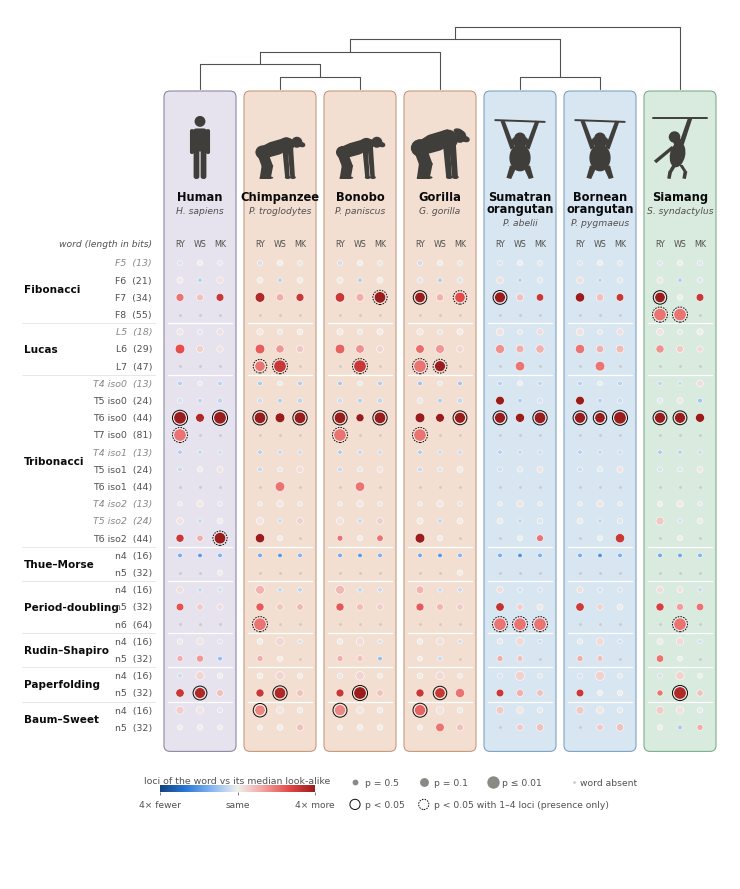

In [ ]:
"""Primate figure: mathematical words vs their look-alikes in seven complete genomes.

usage:  python3 fig_primates.py <all_genomes folder> [out_stem]
In a Jupyter notebook call main('<all_genomes folder>', '<out_stem>') instead.
Text and circle sizes: TEXT_SCALE and DOT_SCALE below, or
        main(folder, out, text_scale=1.2, dot_scale=1.5)

One tinted column per genome (all seven, in phylogenetic order under a
cladogram, each with a primate silhouette). Inside each column, one dot per
word (rows) and encoding (RY, WS, MK), from decoy_test_summary_all_genomes.csv:
  colour  log2 of the word's genome-wide loci over its median decoy's
          (red: more than its look-alikes, blue: fewer)
  size    evidence, -log10 p
  ring    nominal p < 0.05 (dashed: 1-4 loci against decoys with none)
A genome without results yet is drawn with "results pending".
Writes <out_stem>.pdf and <out_stem>.png.
"""
from __future__ import annotations

import os
import sys

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.patches import Circle, Ellipse, FancyBboxPatch, Polygon

# ---------------------------------------------------------------- settings
TEXT_SCALE = 1.0      # all text: 1.2 = 20% larger, 0.9 = 10% smaller
DOT_SCALE = 1.0       # area of every circle (dots, rings, legend): 1.5 = 50% larger
TREE = ((((('chm13', ('chimpanzee', 'bonobo')), 'gorilla'),
          ('sumatran_orangutan', 'bornean_orangutan')), 'siamang'))
ORDER = ['chm13', 'chimpanzee', 'bonobo', 'gorilla', 'sumatran_orangutan', 'bornean_orangutan', 'siamang']
NAME = {'chm13': 'Human', 'chimpanzee': 'Chimpanzee', 'bonobo': 'Bonobo', 'gorilla': 'Gorilla',
        'sumatran_orangutan': 'Sumatran\norangutan', 'bornean_orangutan': 'Bornean\norangutan',
        'siamang': 'Siamang'}
LATIN = {'chm13': 'H. sapiens', 'chimpanzee': 'P. troglodytes', 'bonobo': 'P. paniscus',
         'gorilla': 'G. gorilla', 'sumatran_orangutan': 'P. abelii', 'bornean_orangutan': 'P. pygmaeus',
         'siamang': 'S. syndactylus'}
TINT = {'chm13': '#e6e3ee', 'chimpanzee': '#f3dfd2', 'bonobo': '#f3dfd2', 'gorilla': '#f3dfd2',
        'sumatran_orangutan': '#d8e6f2', 'bornean_orangutan': '#d8e6f2', 'siamang': '#d9eadf'}
EDGE = {'chm13': '#8f88a6', 'chimpanzee': '#c99a7c', 'bonobo': '#c99a7c', 'gorilla': '#c99a7c',
        'sumatran_orangutan': '#7fa3c4', 'bornean_orangutan': '#7fa3c4', 'siamang': '#7fae8d'}
MAPPINGS = ['RY', 'WS', 'MK']
FAMILY = {'fibonacci': 'Fibonacci', 'lucas': 'Lucas', 'tribonacci': 'Tribonacci',
          'thue_morse': 'Thue–Morse', 'period_doubling': 'Period-doubling',
          'rudin_shapiro': 'Rudin–Shapiro', 'paperfolding': 'Paperfolding', 'baum_sweet': 'Baum–Sweet'}

INK, INK2, MUTED, SURF, FIG = '#0b0b0b', '#52514e', '#8a8984', '#ffffff', '#3f3e3b'
CMAP = LinearSegmentedColormap.from_list('div', ['#104281', '#2a78d6', '#86b6ef', '#f0efec',
                                                 '#f2a3a0', '#e34948', '#9b1c1c'])
NORM = TwoSlopeNorm(vmin=-2, vcenter=0, vmax=2)

mpl.rcParams.update({
    'font.family': 'Inter' if 'Inter' in {f.name for f in mpl.font_manager.fontManager.ttflist} else 'DejaVu Sans',
    'font.size': 7, 'figure.facecolor': SURF, 'savefig.facecolor': SURF, 'pdf.fonttype': 42})


# ------------------------------------------------------------ silhouettes
def _p(ax, patch, c):
    patch.set_facecolor(c); patch.set_edgecolor('none'); patch.set_zorder(8); ax.add_patch(patch)


def _line(ax, xs, ys, c):
    ax.plot(xs, ys, color=c, lw=1.4, solid_capstyle='round', zorder=8)


def human(ax, cx, base, h, c):
    u = h / 10
    _p(ax, Circle((cx, base + 9.0 * u), 0.85 * u), c)
    _p(ax, FancyBboxPatch((cx - 1.2 * u, base + 4.3 * u), 2.4 * u, 3.6 * u,
                          boxstyle=f'round,pad=0,rounding_size={0.7 * u}'), c)
    for s in (-1, 1):
        _p(ax, FancyBboxPatch((cx + s * 1.25 * u - 0.32 * u, base + 3.9 * u), 0.64 * u, 3.9 * u,
                              boxstyle=f'round,pad=0,rounding_size={0.3 * u}'), c)
        _p(ax, FancyBboxPatch((cx + s * 0.55 * u - 0.45 * u, base), 0.9 * u, 4.8 * u,
                              boxstyle=f'round,pad=0,rounding_size={0.4 * u}'), c)


def knuckle_walker(ax, cx, base, h, c, bulk=1.0, crest=False):
    """African ape on all fours, facing right: sloping back, long arms, bent legs."""
    u, k = h / 10, bulk
    trunk = [(cx - 3.9 * u, base + 4.6 * u), (cx - 3.6 * u, base + 5.9 * u), (cx - 1.5 * u, base + 7.0 * u * k ** 0.3),
             (cx + 1.6 * u, base + 7.9 * u * k ** 0.3), (cx + 2.7 * u, base + 7.6 * u), (cx + 2.9 * u, base + 6.0 * u),
             (cx + 0.5 * u, base + 4.7 * u), (cx - 2.4 * u, base + 3.9 * u)]
    _p(ax, Polygon(trunk, closed=True), c)
    _p(ax, Ellipse((cx - 2.8 * u, base + 5.1 * u), 2.8 * u * k, 2.6 * u * k), c)
    _p(ax, Ellipse((cx + 1.7 * u, base + 6.5 * u), 3.0 * u * k, 2.9 * u * k), c)
    hx, hy = cx + 3.7 * u, base + 7.0 * u
    _p(ax, Circle((hx, hy), 1.05 * u), c)
    _p(ax, Ellipse((hx + 0.95 * u, hy - 0.45 * u), 1.35 * u, 1.0 * u, angle=-15), c)
    if crest:
        _p(ax, Ellipse((hx - 0.25 * u, hy + 0.85 * u), 1.6 * u, 0.9 * u, angle=-15), c)
    aw = 0.55 * u * k ** 0.5
    for dx in (1.4, 2.4):
        _p(ax, Polygon([(cx + dx * u - aw, base + 6.6 * u), (cx + dx * u + aw, base + 6.6 * u),
                        (cx + (dx + 0.5) * u + aw * 0.8, base + 0.35 * u),
                        (cx + (dx + 0.5) * u - aw * 0.8, base + 0.35 * u)]), c)
        _p(ax, Ellipse((cx + (dx + 0.55) * u, base + 0.3 * u), 1.1 * u, 0.6 * u), c)
    lw_ = 0.6 * u * k ** 0.5
    for dx in (-3.3, -2.3):
        knee = (cx + (dx + 0.9) * u, base + 2.4 * u)
        _p(ax, Polygon([(cx + dx * u - lw_, base + 4.8 * u), (cx + dx * u + lw_, base + 4.8 * u),
                        (knee[0] + lw_, knee[1]), (knee[0] - lw_, knee[1])]), c)
        _p(ax, Polygon([(knee[0] - lw_, knee[1] + 0.2 * u), (knee[0] + lw_, knee[1] + 0.2 * u),
                        (knee[0] + 0.1 * u, base), (knee[0] - 1.0 * u, base)]), c)
        _p(ax, Ellipse((knee[0] - 0.2 * u, base + 0.25 * u), 1.6 * u, 0.5 * u), c)


def orangutan(ax, cx, base, h, c):
    u = h / 10
    _line(ax, [cx - 4.2 * u, cx + 4.2 * u], [base + 10 * u, base + 9.7 * u], c)
    for s in (-1, 1):
        _p(ax, Polygon([(cx + s * 2.6 * u, base + 9.9 * u), (cx + s * 3.3 * u, base + 9.8 * u),
                        (cx + s * 1.6 * u, base + 5.0 * u), (cx + s * 0.9 * u, base + 5.4 * u)]), c)
    _p(ax, Ellipse((cx, base + 3.6 * u), 3.6 * u, 4.6 * u), c)
    _p(ax, Ellipse((cx, base + 6.4 * u), 2.9 * u, 1.9 * u), c)
    _p(ax, Circle((cx, base + 6.9 * u), 1.0 * u), c)
    for s in (-1, 1):
        _p(ax, Polygon([(cx + s * 0.6 * u, base + 2.0 * u), (cx + s * 1.7 * u, base + 2.3 * u),
                        (cx + s * 2.3 * u, base + 0.2 * u), (cx + s * 1.5 * u, base)]), c)


def gibbon(ax, cx, base, h, c):
    u = h / 10
    _line(ax, [cx - 4.4 * u, cx + 4.4 * u], [base + 10 * u, base + 10 * u], c)
    _p(ax, Polygon([(cx + 1.3 * u, base + 10.0 * u), (cx + 2.0 * u, base + 9.9 * u),
                    (cx + 0.6 * u, base + 5.6 * u), (cx - 0.1 * u, base + 6.0 * u)]), c)
    _p(ax, Ellipse((cx - 0.4 * u, base + 4.0 * u), 2.5 * u, 4.2 * u, angle=-12), c)
    _p(ax, Circle((cx - 0.9 * u, base + 6.9 * u), 0.95 * u), c)
    _p(ax, Circle((cx - 0.3 * u, base + 5.95 * u), 0.75 * u), c)
    _p(ax, Polygon([(cx - 1.4 * u, base + 5.4 * u), (cx - 0.9 * u, base + 5.1 * u),
                    (cx - 3.9 * u, base + 2.6 * u), (cx - 4.3 * u, base + 3.0 * u)]), c)
    for dx, kx in ((-0.9, -1.6), (0.1, 0.9)):
        _p(ax, Polygon([(cx + (dx - 0.3) * u, base + 2.4 * u), (cx + (dx + 0.35) * u, base + 2.3 * u),
                        (cx + (kx + 0.3) * u, base + 1.1 * u), (cx + (kx - 0.3) * u, base + 1.2 * u)]), c)
        _p(ax, Polygon([(cx + (kx - 0.3) * u, base + 1.3 * u), (cx + (kx + 0.3) * u, base + 1.2 * u),
                        (cx + (kx + 0.05) * u, base), (cx + (kx - 0.5) * u, base + 0.1 * u)]), c)


def icon(ax, g, cx, base, h, c=FIG):
    if g == 'chm13':
        human(ax, cx, base, h, c)
    elif g in ('chimpanzee', 'bonobo'):
        knuckle_walker(ax, cx - 0.04 * h, base, h * 0.82, c, bulk=0.92 if g == 'bonobo' else 1.0)
    elif g == 'gorilla':
        knuckle_walker(ax, cx - 0.04 * h, base, h * 0.95, c, bulk=1.12, crest=True)
    elif 'orangutan' in g:
        orangutan(ax, cx, base, h * 0.92, c)
    else:
        gibbon(ax, cx, base, h * 0.95, c)


# ------------------------------------------------------------------ helpers
def draw_tree(ax, t, xpos, y0, height):
    def depth(n):
        return 0 if isinstance(n, str) else 1 + max(depth(c) for c in n)
    D = depth(t)

    def rec(n):
        if isinstance(n, str):
            return xpos[n], 0
        pts = [rec(c) for c in n]
        d = 1 + max(p[1] for p in pts)
        y = y0 + height * d / D
        for x, dc in pts:
            ax.plot([x, x], [y0 + height * dc / D, y], color=INK2, lw=0.8, solid_capstyle='round')
        ax.plot([min(p[0] for p in pts), max(p[0] for p in pts)], [y, y], color=INK2, lw=0.8,
                solid_capstyle='round')
        return np.mean([p[0] for p in pts]), d
    rec(t)


def word_rows(d):
    present = d.groupby('pattern').real_loci.max()
    w = (d[d.pattern.isin(present[present > 0].index)][['pattern', 'family', 'variant', 'label', 'length']]
         .drop_duplicates('pattern'))
    w['fo'] = w.family.map(list(FAMILY).index)
    w = w.sort_values(['fo', 'variant', 'length']).reset_index(drop=True)
    w['testable'] = w.pattern.map(d.groupby('pattern').testable.all())
    return w, d.pattern.nunique() - len(w)


def word_name(r):
    v = '' if r.variant == 'standard' else f" {r.variant.replace('isolate_', 'iso')}"
    return f"{r.label}{v}  ({r.length})"


def fs(x):
    return x * TEXT_SCALE


def size(ev):
    return DOT_SCALE * (7 + 46 * np.clip(np.asarray(ev, float) / 2.0, 0, 1) ** 1.2)


# --------------------------------------------------------------------- main
def main(folder, out, text_scale=None, dot_scale=None):
    global TEXT_SCALE, DOT_SCALE
    TEXT_SCALE = TEXT_SCALE if text_scale is None else text_scale
    DOT_SCALE = DOT_SCALE if dot_scale is None else dot_scale
    d = pd.read_csv(os.path.join(folder, 'decoy_test_summary_all_genomes.csv'))
    if 'in_shared_set' in d:
        d = d[d.in_shared_set]
    have = set(d.genome)
    w, n_absent = word_rows(d)
    nw = len(w)

    W, H = 7.2, 8.5
    extra = 0.2 if TEXT_SCALE > 1.05 else 0.0     # room for a three-line footnote
    fig = plt.figure(figsize=(W, H + extra))
    ax = fig.add_axes([0, 0, 1, 1]); ax.set_xlim(0, W); ax.set_ylim(-extra, H); ax.axis('off'); ax.set_aspect('equal')

    left = 1.5                                   # word and family labels
    colw = (W - left - 0.1) / len(ORDER)
    cx = {g: left + (i + 0.5) * colw for i, g in enumerate(ORDER)}
    sub = colw * 0.25                            # spacing of RY / WS / MK inside a column
    xmap = {(g, m): cx[g] + (j - 1) * sub for g in ORDER for j, m in enumerate(MAPPINGS)}

    row_h = 0.172
    y_top = 5.96                                 # first word row
    yrow = {p: y_top - i * row_h for i, p in enumerate(w.pattern)}
    col_top, col_bot = 7.68, y_top - (nw - 1) * row_h - 0.24

    # cladogram above the columns
    draw_tree(ax, TREE, cx, col_top + 0.02, 0.62)

    for g in ORDER:
        c = cx[g]
        ax.add_patch(FancyBboxPatch((c - colw * 0.45, col_bot), colw * 0.9, col_top - col_bot,
                                    boxstyle='round,pad=0,rounding_size=0.06',
                                    fc=TINT[g], ec=EDGE[g], lw=0.8, zorder=2))
        icon(ax, g, c, 6.8, min(0.78, colw * 0.8))
        ax.text(c, 6.68, NAME[g], ha='center', va='top', fontsize=fs(6.6), color=INK, zorder=9,
                fontweight='semibold', linespacing=0.95)
        ax.text(c, 6.68 - (0.27 if '\n' in NAME[g] else 0.15), LATIN[g], ha='center', va='top',
                fontsize=fs(5.3), style='italic', color=INK2, zorder=9)
        for m in MAPPINGS:
            ax.text(xmap[(g, m)], y_top + 0.15, m, fontsize=fs(4.6), ha='center', va='bottom', color=INK2, zorder=9)

    ax.text(left - 0.08, y_top + 0.19, 'word (length in bits)', ha='right', va='center', fontsize=fs(5.3),
            color=INK2, style='italic')

    # family separators and labels
    prev = None
    for i, r in w.iterrows():
        if r.family != prev and i > 0:
            yy = y_top - (i - 0.5) * row_h
            for g in ORDER:
                ax.plot([cx[g] - colw * 0.4, cx[g] + colw * 0.4], [yy, yy], color='#ffffff', lw=0.9, zorder=3)
            ax.plot([0.12, left - 0.05], [yy, yy], color='#e4e3df', lw=0.6, zorder=3)
        prev = r.family
    for fam, grp in w.groupby('family', sort=False):
        ys = [yrow[p] for p in grp.pattern]
        ax.text(0.14, np.mean(ys), FAMILY[fam], ha='left', va='center', fontsize=fs(6), color=INK,
                fontweight='semibold', zorder=9)
    for r in w.itertuples():
        ax.text(left - 0.08, yrow[r.pattern], word_name(r), ha='right', va='center', fontsize=fs(5.4),
                color=INK2 if r.testable else MUTED, style='normal' if r.testable else 'italic', zorder=9)

    # dots
    x = d[d.pattern.isin(yrow)].copy()
    x['xx'] = [xmap[(g, m)] for g, m in zip(x.genome, x.mapping)]
    x['yy'] = x.pattern.map(yrow)
    x['lfc'] = np.log2((x.real_loci + 1) / (x.decoy_loci_median + 1))
    x['ev'] = -np.log10(x.p_emp_loci.clip(lower=1e-3))
    absent, pres = x[x.real_loci == 0], x[x.real_loci > 0]
    ax.scatter(absent.xx, absent.yy, s=2.5 * DOT_SCALE, c='#c9c8c3', lw=0, zorder=4)
    ax.scatter(pres.xx, pres.yy, s=size(pres.ev), c=pres.lfc, cmap=CMAP, norm=NORM,
               edgecolors=SURF, linewidths=0.4, zorder=5)
    nom = pres[pres.p_emp_loci < 0.05]
    for few, ls in ((False, '-'), (True, (0, (1.6, 1.2)))):
        q = nom[(nom.real_loci < 5) == few]
        ax.scatter(q.xx, q.yy, s=size(q.ev) + 26 * DOT_SCALE, facecolors='none', edgecolors=INK, linewidths=0.7,
                   linestyles=ls, zorder=6)
    for g in ORDER:
        if g not in have:
            ax.text(cx[g], y_top - (nw - 1) * row_h / 2, 'results\npending', ha='center', va='center',
                    fontsize=fs(6), style='italic', color=MUTED, zorder=9, rotation=90, linespacing=1.2)

    # legend
    ly = col_bot - 0.38
    cax = fig.add_axes([left / W, (ly - 0.03 + extra) / (H + extra), 1.55 / W, 0.07 / (H + extra)])
    cb = fig.colorbar(mpl.cm.ScalarMappable(norm=NORM, cmap=CMAP), cax=cax, orientation='horizontal')
    cb.set_ticks([-2, 0, 2]); cb.set_ticklabels(['4× fewer', 'same', '4× more'])
    cb.ax.tick_params(labelsize=fs(5.2), length=2, width=0.5, color=INK2, labelcolor=INK2)
    cb.outline.set_visible(False)
    cax.set_title('loci of the word vs its median look-alike', fontsize=fs(5.4), color=INK2, pad=2)
    sx = left + 1.95
    k_ = max(1.0, TEXT_SCALE)                    # legend spacing grows with the text
    r_ = 0.08 * max(1.0, DOT_SCALE ** 0.5)      # gap between a legend circle and its label
    for k, (ev, lab) in enumerate([(0.3, 'p = 0.5'), (1.0, 'p = 0.1'), (2.0, 'p ≤ 0.01')]):
        ax.scatter([sx + 0.55 * k_ * k], [ly + 0.07], s=size([ev]), color=MUTED, lw=0)
        ax.text(sx + 0.55 * k_ * k + r_, ly + 0.07, lab, fontsize=fs(5.3), va='center', color=INK2)
    ax.scatter([sx], [ly - 0.15], s=36 * DOT_SCALE, facecolors='none', edgecolors=INK, lw=0.7)
    ax.text(sx + r_, ly - 0.15, 'p < 0.05', fontsize=fs(5.3), va='center', color=INK2)
    ax.scatter([sx + 0.55 * k_], [ly - 0.15], s=36 * DOT_SCALE, facecolors='none', edgecolors=INK, lw=0.7, linestyles=[(0, (1.6, 1.2))])
    ax.text(sx + 0.55 * k_ + r_, ly - 0.15, 'p < 0.05 with 1–4 loci (presence only)', fontsize=fs(5.3), va='center', color=INK2)
    ax.scatter([sx + 1.75 * k_], [ly + 0.07], s=2.5 * DOT_SCALE, c='#c9c8c3', lw=0)
    ax.text(sx + 1.75 * k_ + 0.06, ly + 0.07, 'word absent', fontsize=fs(5.3), va='center', color=INK2)


    fig.savefig(out + '.pdf'); fig.savefig(out + '.png', dpi=300)
    print('wrote', out + '.pdf', out + '.png', '| with results:', ', '.join(g for g in ORDER if g in have))


if __name__ == '__main__':
    args = [a for a in sys.argv[1:] if not a.startswith('-')]      # ignores Jupyter's --f=...
    main('/Users/kleiopapatheodorou/Documents/lab/fibonacci/patterns/results_new/all_genomes',
     '/Users/kleiopapatheodorou/Documents/lab/fibonacci/patterns/results_new/all_genomes/fig_primates',
     text_scale=1.25, dot_scale=1.5)